# Классификация ботов

Чтобы вкратце узнать суть этого ноутбука, прочитайте файл `MODEL.md`

In [1376]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from metric import precision_at_recall


## Первичная очистка данных

In [1377]:
# загружаем датасеты
train = pd.read_csv(
    "data/train.csv",
    parse_dates=["cookie_created_at", "window_start_ts", "window_end_ts"],
)
test = pd.read_csv(
    "data/test.csv",
    parse_dates=["cookie_created_at", "window_start_ts", "window_end_ts"],
)
raw_events = pd.read_csv("data/events.csv.gz", parse_dates=["event_ts"])

Обработаем повторы в данных. У нас нет уникальных идентификаторов событий, поэтому мы не можем однозначно определить повторы как ошибки в таблице или как действительно повторяющиеся события.

In [1378]:
print(raw_events.duplicated().sum())
print(raw_events.shape)
print(raw_events.duplicated().sum() / raw_events.shape[0])


4863
(328905, 14)
0.01478542436265791


Повторов в данных около полутора процентов. Сохраним в `event_repeat_count` кратность каждой исходной строки, включая первое появление, а затем удалим дубликаты.

In [1379]:
raw_events["event_repeat_count"] = (
    raw_events
    .groupby(raw_events.columns.tolist(), dropna=False)[raw_events.columns.tolist()[0]]
    .transform("size")
)

events_clean = raw_events.drop_duplicates().copy()

Очистим события, не попадающие в заданные временные окна.

In [1380]:
# выделяем признаки по временным окнам
def events_in_window(events, meta):
    meta_cols = ["cookie_id", "window_start_ts", "window_end_ts"]
    if "target" in meta.columns:
        meta_cols.append("target")
    if "dataset" in meta.columns:
        meta_cols.append("dataset")

    ev = events.merge(meta[meta_cols], on="cookie_id", how="inner")

    return ev[
        (ev["event_ts"] >= ev["window_start_ts"])
        & (ev["event_ts"] < ev["window_end_ts"])
    ]


events_train = events_in_window(events_clean, train)  # обучающая выборка
events_test = events_in_window(events_clean, test)  # тестовая выборка

## Выбор стратегии для обучения и тестирования модели

Чтобы в дальнейшем иметь возможность проверять разные модели и подбирать наилучшую, также разделим `events_train` на обучающую и валидационную выборку. Разделять будем по времени во избежание лика данных.

Логически данные разделены по временным окнам, давайте посмотрим на вид этих временных окон.

In [1381]:
windows = (
    train[["window_start_ts", "window_end_ts"]]
    .drop_duplicates()
    .sort_values(["window_start_ts", "window_end_ts"])
    .reset_index(drop=True)
)

windows

,window_start_ts,window_end_ts
0,2026-04-06,2026-04-07
1,2026-04-07,2026-04-08
2,2026-04-08,2026-04-09
3,2026-04-09,2026-04-10
4,2026-04-10,2026-04-11
5,2026-04-11,2026-04-12
6,2026-04-12,2026-04-13
7,2026-04-13,2026-04-14
8,2026-04-14,2026-04-15
9,2026-04-15,2026-04-16


Их всего 14 и каждое из них это 1 сутки. Тогда разделение по времени будем делать на основе этих временных окон, например по `window_end_ts`.

Сделаем валидационной выборкой последние два дня, удалим их из `events_train` и проведем на этих данных финальное тестирование моделей.

In [1382]:
validation_dates = (
    train["window_start_ts"]
    .dt.normalize()
    .drop_duplicates()
    .sort_values()
    .iloc[-2:]
)

all_train_events = events_in_window(events_clean, train)
is_validation_event = all_train_events["window_start_ts"].dt.normalize().isin(
    validation_dates
)
events_validation = all_train_events.loc[is_validation_event].copy()
events_train = all_train_events.loc[~is_validation_event].copy()

В условии указано, что мы должны научиться предсказывать некий `score` для каждой куки. Но текущая таблица это таблица событий, в которой одна и та же кука может находиться в куче разных строк. В том числе некоторые куки могут иметь больше событий, чем другие и мы хотим, чтобы это количество событий стало признаком для этой куки, а не чтобы она учлась для модели больше, чем другие.

Поэтому давайте создадим новую таблицу: `features` используя `events.csv.gz`, `train.csv`, `test.csv`. `features` будет содержать новые признаки для каждой куки и именно на этих данных модель будет предсказывать `score`. Фичи мы не будем разделять, поскольку большинство работы по созданию признаков будет актуально для всей таблицы. В дальнейшем, при обучении, будем выбирать нужные нам строки этой таблицы для обучения и тестирования моделей.

Сначала построим одну таблицу со всеми данными нам уникальными куками и информацией о них.

In [1383]:
cookies = pd.concat(
    [train.assign(dataset="train"), test.assign(dataset="test")],
    ignore_index=True,
).set_index("cookie_id")

events = events_in_window(events_clean, cookies.reset_index("cookie_id"))

In [1384]:
# Теперь сконструируем признаки для каждой куки.
features = cookies.copy()

# сразу добавим фичу полученную из дубликатов
features["event_repeat_count"] = (
    events["event_repeat_count"]
    .sub(1)
    .groupby(events["cookie_id"])
    .sum()
    .reindex(features.index, fill_value=0)
    .astype("int64")
)

Теперь проведем EDA на обучающей части данных, чтобы сгенерировать новые признаки и выбрать стратегии для исправления проблем в данных, которые затем будут независимо реализовываться в каждой тренировочной выборке, чтобы избежать лика данных.

## EDA и генерация фич

In [1385]:
events_train.head()

,cookie_id,event_ts,eid,event_name,platform,user_agent,item_id,item_category,item_location,seller_type,search_query,search_page,pointer_x,pointer_y,event_repeat_count,window_start_ts,window_end_ts,target
0,ck_d274382b19488771,2026-04-13 12:02:56,200,item_view,WEB,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,1048743.0,kvartiry_prodazha,kirov,private,NaN,NaN,675.0,276.0,1,2026-04-13,2026-04-14,0
1,ck_fbbed2ff14944ce9,2026-04-08 06:12:14,100,search_results_view,web,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,bytovaya_tehnika,novosibirsk,NaN,пылесос dyson,2.0,NaN,NaN,1,2026-04-08,2026-04-09,0
2,ck_56cc15c7c634cb9f,2026-04-12 17:16:05,100,search_results_view,WEB,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,odezhda,sankt-peterburg,NaN,костюм мужской,2.0,NaN,NaN,1,2026-04-12,2026-04-13,0
4,ck_f80d85f038cdacee,2026-04-11 16:08:12,200,item_view,desktop,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,1000845.0,bytovaya_tehnika,sankt-peterburg,private,NaN,NaN,NaN,NaN,1,2026-04-11,2026-04-12,0
5,ck_e4f046f721d10f81,2026-04-10 16:50:05,200,item_view,IOS,Mozilla/5.0 (iPhone; CPU iPhone OS 15_2 like M...,1055188.0,telefony,ekaterinburg,pro,NaN,NaN,NaN,NaN,1,2026-04-10,2026-04-11,0


In [1386]:
events_train.info()

<class 'pandas.DataFrame'>
Index: 172276 entries, 0 to 235692
Data columns (total 18 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   cookie_id           172276 non-null  str           
 1   event_ts            172276 non-null  datetime64[us]
 2   eid                 172276 non-null  int64         
 3   event_name          172276 non-null  str           
 4   platform            172276 non-null  str           
 5   user_agent          172276 non-null  str           
 6   item_id             115299 non-null  float64       
 7   item_category       158647 non-null  str           
 8   item_location       163754 non-null  str           
 9   seller_type         104823 non-null  str           
 10  search_query        53560 non-null   str           
 11  search_page         53560 non-null   float64       
 12  pointer_x           57866 non-null   float64       
 13  pointer_y           57866 non-null   float64 

Числовые признаки: 
- `search_page`, 
- `pointer_x`, 
- `pointer_y`. 
  
Категориальные признаки: 
- `cookie_id`, 
- `eid`, 
- `event_name`, 
- `platform`, 
- `user_agent`, 
- `item_id`, 
- `item_category`, 
- `item_location`, 
- `seller_type`, 
- `search_query`, 
- `target`.
  
Временные признаки:
- `event_ts`
- `window_start_ts`
- `window_end_ts`

In [1387]:
number_features = ["search_page", "pointer_x", "pointer_y"]
categorical_features = [
    "cookie_id",
    "eid",
    "event_name",
    "platform",
    "user_agent",
    "item_id",
    "item_category",
    "item_location",
    "seller_type",
    "search_query",
]
time_features = ["event_ts", "window_start_ts", "window_end_ts"]
target = ["target"]

In [1388]:
events_train.isna().sum()

cookie_id                  0
event_ts                   0
eid                        0
event_name                 0
platform                   0
user_agent                 0
item_id                56977
item_category          13629
item_location           8522
seller_type            67453
search_query          118716
search_page           118716
pointer_x             114410
pointer_y             114410
event_repeat_count         0
window_start_ts            0
window_end_ts              0
target                     0
dtype: int64

В данных присутствуют пропуски. Большинство из них не представляют проблемы, так как не у всех событий есть соответствующие фичи. В дальнейшем, за исключением бейзлайна, будем работать с моделями, которые умеют корректно обрабатывать пропуски и учитывать их, как информацию.

### Числовые признаки

Проведем визуальный анализ данных. Для начала построим гистограммы.

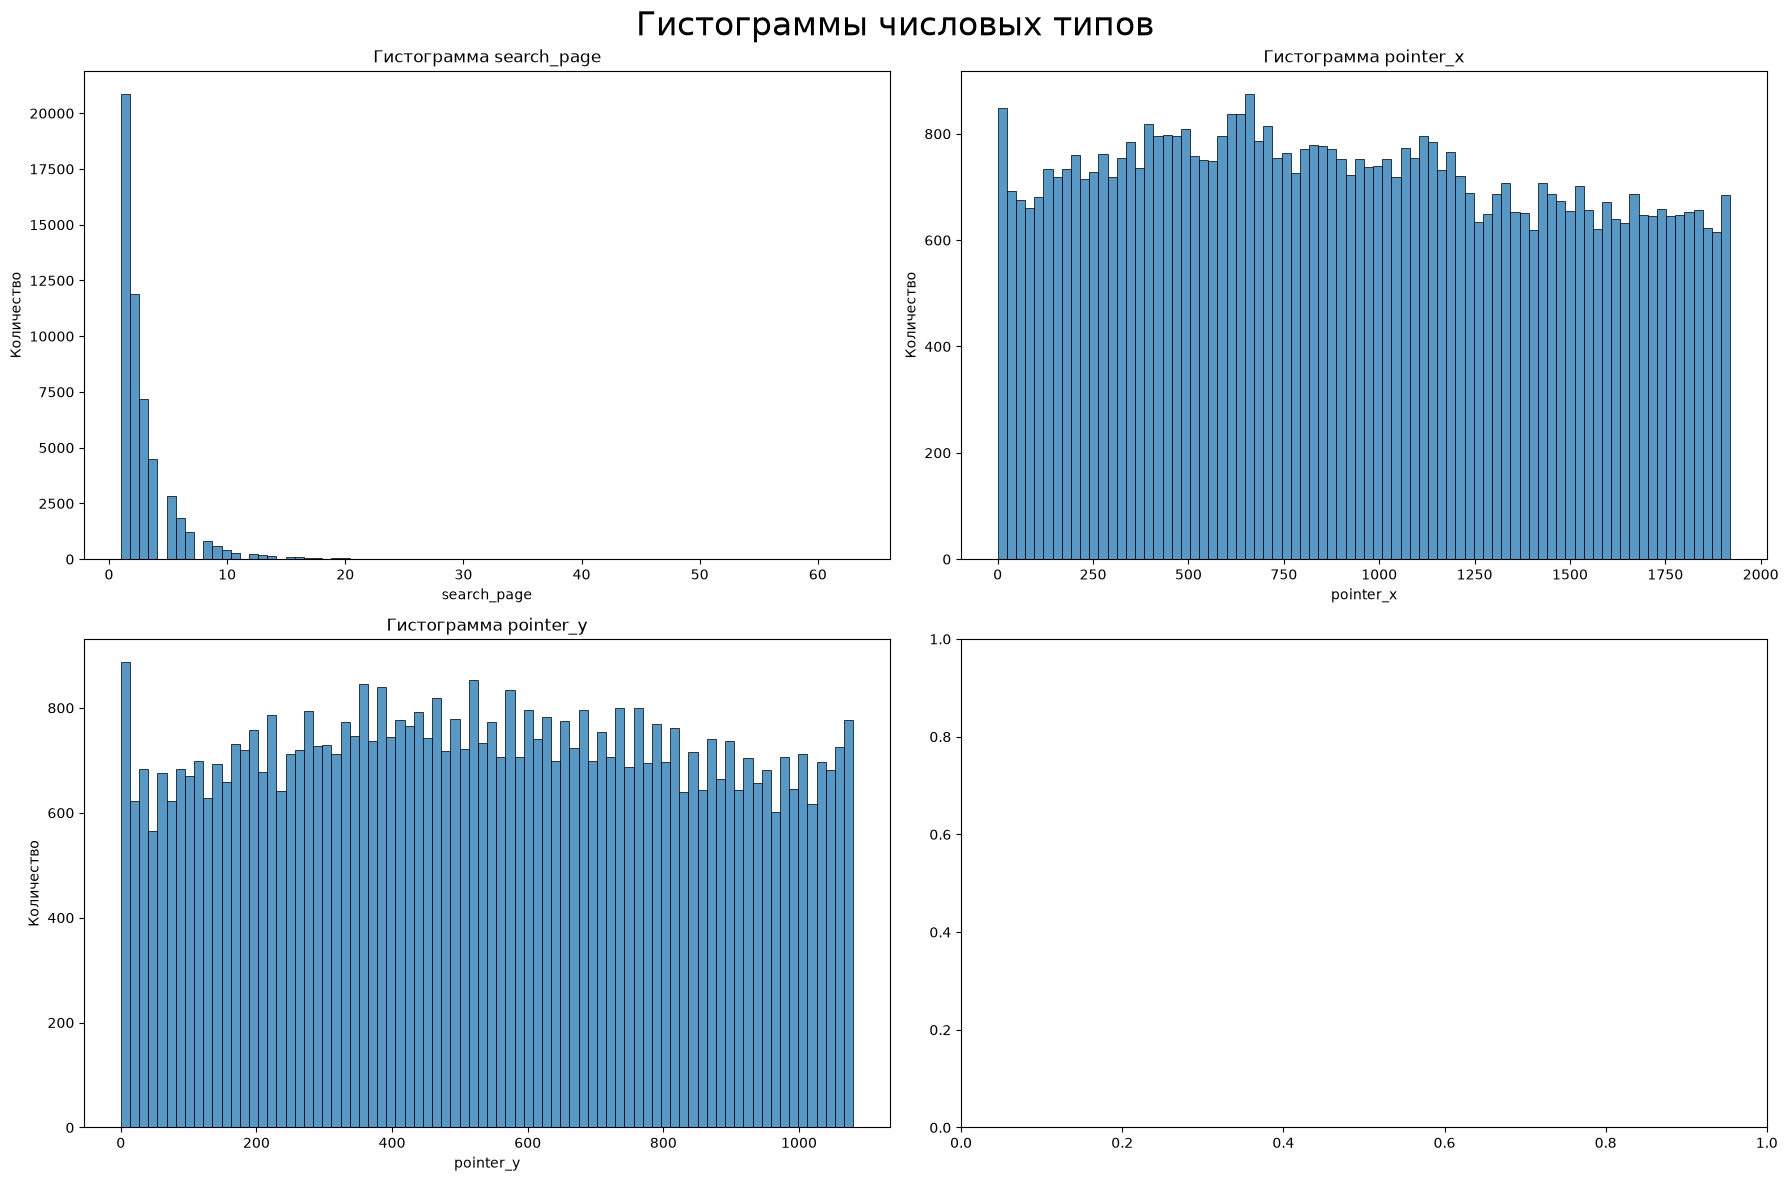

In [1389]:
cols = 2
rows = math.ceil(len(number_features) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 9, rows * 6))
axes = axes.flatten()

for i, col in enumerate(number_features):
    sns.histplot(events_train[col], bins=80, ax=axes[i])  # type: ignore
    axes[i].set_title(f"Гистограмма {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Количество")

fig.suptitle("Гистограммы числовых типов", fontsize=24)
plt.tight_layout()
plt.show()

1. `search_page` $-$ ожидаемые результаты, большая часть запросов приходится на первые страницы. Но в данных есть явные выбросы: страницы после 20. Для нашей задачи такие данные очень полезны, потому что нетипичное поведение будет хорошо разделять классы. Тогда добавим дополнительную `bool` фичу: является ли запрос "глубоким" в таблицу событий и с ее помощью построим соответствующие фичи для `features`.
2. `pointer_x` и `pointer_y` $-$ данные распределены почти равномерно. У нас нет данных о разрешении экрана пользователя, поэтому нормализовать данные не получится, несмотря на то, что уже в `head()` в колонке `user_agent` видно, что у нас есть данных и с компьютеров, и с телефонов. Можно заметить высокий столбик в окрестности нуля, точка `(0; 0)` довольно подозрительна для человека, поэтому мы можем добавить признак расстояния до точки `(0, 0)`.

In [1390]:
# добавление признаков по search_page
events["is_deep_search_page"] = (
    events["search_page"].gt(20).astype("boolean").where(events["search_page"].notna())
)
search_page_aggregated = events.groupby("cookie_id").agg(
    search_count=("search_page", "count"),
    deep_search_count=("is_deep_search_page", "sum"),
    mean_search_page=("search_page", "mean"),
)
features[search_page_aggregated.columns] = search_page_aggregated.reindex(
    features.index
)
features["has_deep_search_page"] = features["deep_search_count"].gt(0)
features["deep_search_share"] = features["deep_search_count"] / features[
    "search_count"
].replace(0, np.nan)

# добавление признаков по pointer_x и pointer_y
events["dist_from_zero"] = np.sqrt(
    events["pointer_x"] * events["pointer_x"]
    + events["pointer_y"] * events["pointer_y"]
)
pointer_aggregated = events.groupby("cookie_id").agg(
    mean_dist_from_zero=("dist_from_zero", "mean"),
    min_dist_from_zero=("dist_from_zero", "min"),
    std_x=("pointer_x", "std"),
    std_y=("pointer_y", "std"),
)
features[pointer_aggregated.columns] = pointer_aggregated.reindex(features.index)

Добавленные признаки:
- `search_count` - количество поисков страниц
- `deep_search_count` - количество поисков на глубоких (больше 20) страницах
- `mean_search_page` - доля поисков на глубоких страницах
- `mean_dist_from_zero` - среднее расстояние до (0; 0)
- `min_dist_from_zero` - минимальное расстояние до (0; 0)
- `std_x` - стандартное отклонение по оси x
- `std_y` - стандартное отклонение по оси y

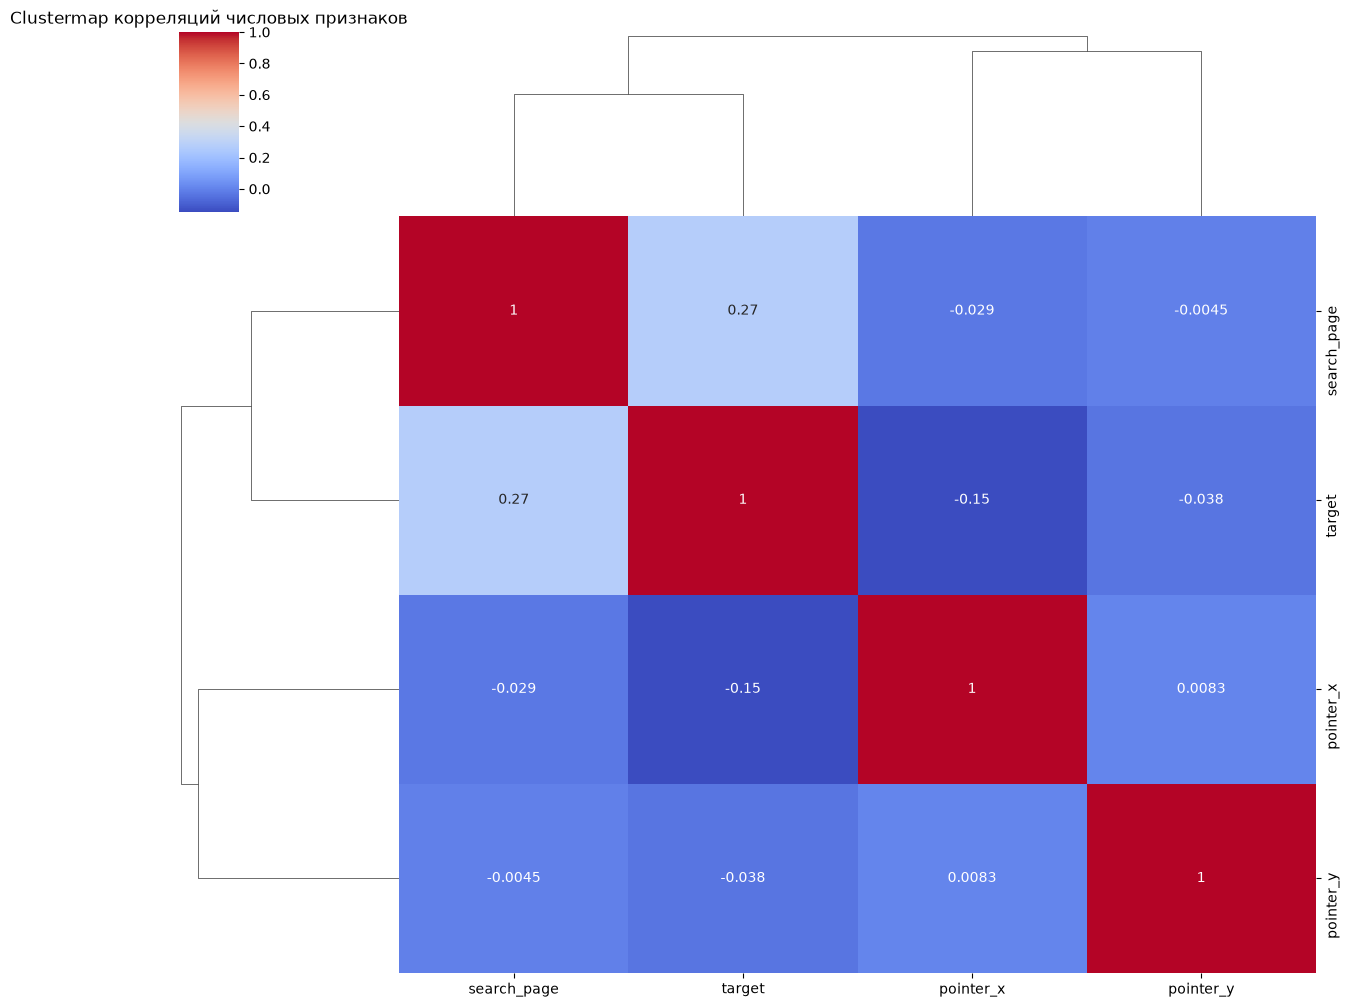

In [1391]:
# построим матрицу корреляций
clustermap_cols = number_features + target
sns.clustermap(
    events_train[clustermap_cols].corr(), cmap="coolwarm", annot=True, figsize=(12, 10)
)
plt.title("Clustermap корреляций числовых признаков")
plt.show()

Видно, что таргет имеет более сильную корреляцию с координатой по оси `x`, чем по оси `y`. Добавим фичу, связанную с осью `x`.

In [1392]:
more_pointer_aggregated = events.groupby("cookie_id").agg(
    mean_x=("pointer_x", "mean"), median_x=("pointer_x", "median")
)
features[more_pointer_aggregated.columns] = more_pointer_aggregated.reindex(
    features.index
)

Добавленные признаки: 
- `mean_x` - среднее значение координаты по оси x
- `median_x` - медианное значение координаты по оси x

### Категориальные признаки

In [1393]:
print(events_train["user_agent"][0])
print(events_train["search_query"][1])

Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/113.0.0.0 YaBrowser/23.5.0.0 Safari/537.36
пылесос dyson


Признаки `user_agent` и `search_query` на данный момент выглядят очень сложно. Давайте разделим их на более простые.
1. `user_agent` содержит много вещей: архитектуру устройства, токены совместимости, движок и так далее. Но можно сделать предположение, что от токенов совместимости мало что зависит. Но остальные характеристики могут быть полезны, несмотря на то, что данные в `user_agent` могут быть поддельными. К примеру, владельцам ботов может быть наиболее удобно использовать конкретную ОС, конкретный браузер или конкретную версию браузера и такие зависимости сильно помогут модели. С другой стороны, реальные пользователи используют совершенно разные устройства, поэтому поддельные данные не сильно ей помешают, так как учитываться в основном будут именно выбросы количества данных, соответствующих людям/ботам. 
2. `search_query` это введенный пользователем запрос и он может содержать самые разнообразные вещи, запросы могут быть разной длины, разной подробности, и так далее.

In [1394]:
# посмотрим на представленные в данных user_agent
ua_inventory = (
    events_train.groupby("user_agent")
    .agg(
        n_events=("cookie_id", "size"),
        n_cookies=("cookie_id", "nunique"),
    )
    .sort_values("n_events", ascending=False)
)

print("Уникальных User-Agent:", len(ua_inventory))
with pd.option_context(
    "display.max_rows",
    None,
):
    display(ua_inventory)

Уникальных User-Agent: 148


,n_events,n_cookies
user_agent,,
"Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36",2103,116
"Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/117.0.0.0 YaBrowser/23.9.0.0 Safari/537.36",2014,138
"Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 YaBrowser/23.0.0.0 Safari/537.36",1980,138
"Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/123.0.0.0 YaBrowser/23.3.0.0 Safari/537.36",1959,106
"Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/119.0.0.0 YaBrowser/23.11.0.0 Safari/537.36",1927,117
"Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/116.0.0.0 YaBrowser/23.8.0.0 Safari/537.36",1887,105
"Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",1876,128
"Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) HeadlessChrome/118.0.0.0 Safari/537.36",1865,70
"Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/121.0.0.0 YaBrowser/23.1.0.0 Safari/537.36",1859,130


Просмотр строк выявил браузеры Chrome, Firefox, Yandex, Safari и Headless Chrome, приложение Avito, а также несколько HTTP-библиотек и инструментов.

Правила применяются от более специфичных к общим, поскольку одна строка может содержать несколько совместимых обозначений: например, Yandex содержит токены Chrome и Safari, Android — Linux, а iPhone — Mac OS X. Если информации недостаточно, сохраняется категория unknown.

In [1395]:
# разделение и добавление в события признаков из user_agent
def parse_user_agent(value):
    s = "" if pd.isna(value) else str(value).casefold()

    rules = [
        ("python-requests/", "requests"),
        ("python-urllib3/", "urllib3"),
        ("node-fetch/", "node_fetch"),
        ("scrapy/", "scrapy"),
        ("curl/", "curl"),
        ("go-http-client/", "go_http"),
        ("avito/", "avito_app"),
        ("headlesschrome/", "headless_chrome"),
        ("yabrowser/", "yandex"),
        ("firefox/", "firefox"),
        ("chrome/", "chrome"),
        ("safari/", "safari"),
    ]

    client_family = "unknown"
    for token, family in rules:
        if token in s:
            client_family = family
            break

    if "android" in s:
        os_family = "android"
    elif "iphone" in s or "ipad" in s:
        os_family = "ios"
    elif "windows" in s:
        os_family = "windows"
    elif "macintosh" in s or "mac os x" in s:
        os_family = "macos"
    elif "linux" in s:
        os_family = "linux"
    else:
        os_family = "unknown"

    http_families = {
        "requests",
        "urllib3",
        "node_fetch",
        "scrapy",
        "curl",
        "go_http",
    }

    return {
        "client_family": client_family,
        "os_family": os_family,
        "is_http_library": client_family in http_families,
        "is_headless": client_family == "headless_chrome",
    }


user_agent_lookup = pd.DataFrame(
    [
        {"user_agent": ua, **parse_user_agent(ua)}
        for ua in events["user_agent"].drop_duplicates()
    ]
)
events = events.merge(
    user_agent_lookup, on="user_agent", how="left", validate="many_to_one"
)

# добавление фич, связанных с user_agent
user_agent_aggregated = events.groupby("cookie_id").agg(
    diff_client_families=("client_family", "nunique"),
    diff_os_families=("os_family", "nunique"),
    user_agent_count=("client_family", "count"),
    http_library_count=("is_http_library", "sum"),
    headless_count=("is_headless", "sum"),
)
features[user_agent_aggregated.columns] = user_agent_aggregated.reindex(features.index)
features["http_library_share"] = (
    features["http_library_count"] / features["user_agent_count"]
)
features["headless_share"] = features["headless_count"] / features["user_agent_count"]
os_to_device = {
    "android": "mobile",
    "ios": "mobile",
    "windows": "desktop",
    "macos": "desktop",
    "linux": "desktop",
}
events["device_type"] = events["os_family"].map(os_to_device).fillna("unknown")
events["is_mobile"] = events["device_type"].eq("mobile")
events["is_desktop"] = events["device_type"].eq("desktop")
events["is_unknown_device"] = events["device_type"].eq("unknown")
device_aggregated = events.groupby("cookie_id").agg(
    phone_share=("is_mobile", "mean"),
    desktop_share=("is_desktop", "mean"),
    unknown_device_share=("is_unknown_device", "mean"),
)
features[device_aggregated.columns] = device_aggregated.reindex(features.index)

ua_categories = {
    "client_family": [
        "requests",
        "urllib3",
        "node_fetch",
        "scrapy",
        "curl",
        "go_http",
        "avito_app",
        "headless_chrome",
        "yandex",
        "firefox",
        "chrome",
        "safari",
    ],
    "os_family": [
        "android",
        "ios",
        "windows",
        "macos",
        "linux",
        "unknown"
    ],
}

prefixes = {
    "client_family": "client_share_",
    "os_family": "os_share_",
}

for column, categories in ua_categories.items():
    labels = events[column]

    counts = pd.crosstab(
        events["cookie_id"],
        labels,
    ).reindex(columns=categories, fill_value=0)

    shares = counts.div(
        counts.sum(axis=1).replace(0, np.nan),
        axis=0,
    )

    shares = shares.add_prefix(prefixes[column])

    features[shares.columns] = shares.reindex(features.index)

features["ua_nunique"] = (
    events.groupby("cookie_id")["user_agent"]
    .nunique()
    .reindex(features.index, fill_value=0)
)

# добавление фич, связанных с search_query
search_query_aggregated = events.groupby("cookie_id").agg(
    search_query_count=("search_query", "count"),
    unique_search_query_count=("search_query", "nunique"),
)
features[search_query_aggregated.columns] = search_query_aggregated.reindex(
    features.index
)
features["unique_search_query_share"] = features[
    "unique_search_query_count"
] / features["search_query_count"].replace(0, np.nan)

Добавленные признаки:
- `diff_client_families` - количество различных клиентов для запросов
- `diff_os_families` - количество различных ОС для запросов
- `user_agent_count` - количество различных `user_agent`
- количества и доли различных браузеров и операционных систем
- `search_query_count` - количество поисковых запросов
- `unique_search_query_count` - количество уникальных поисковых запросов
- `unique_search_query_share` - доля уникальных поисковых запросов

Проведем визуальный анализ остальных категориальных данных. Для начала построим гистограммы.

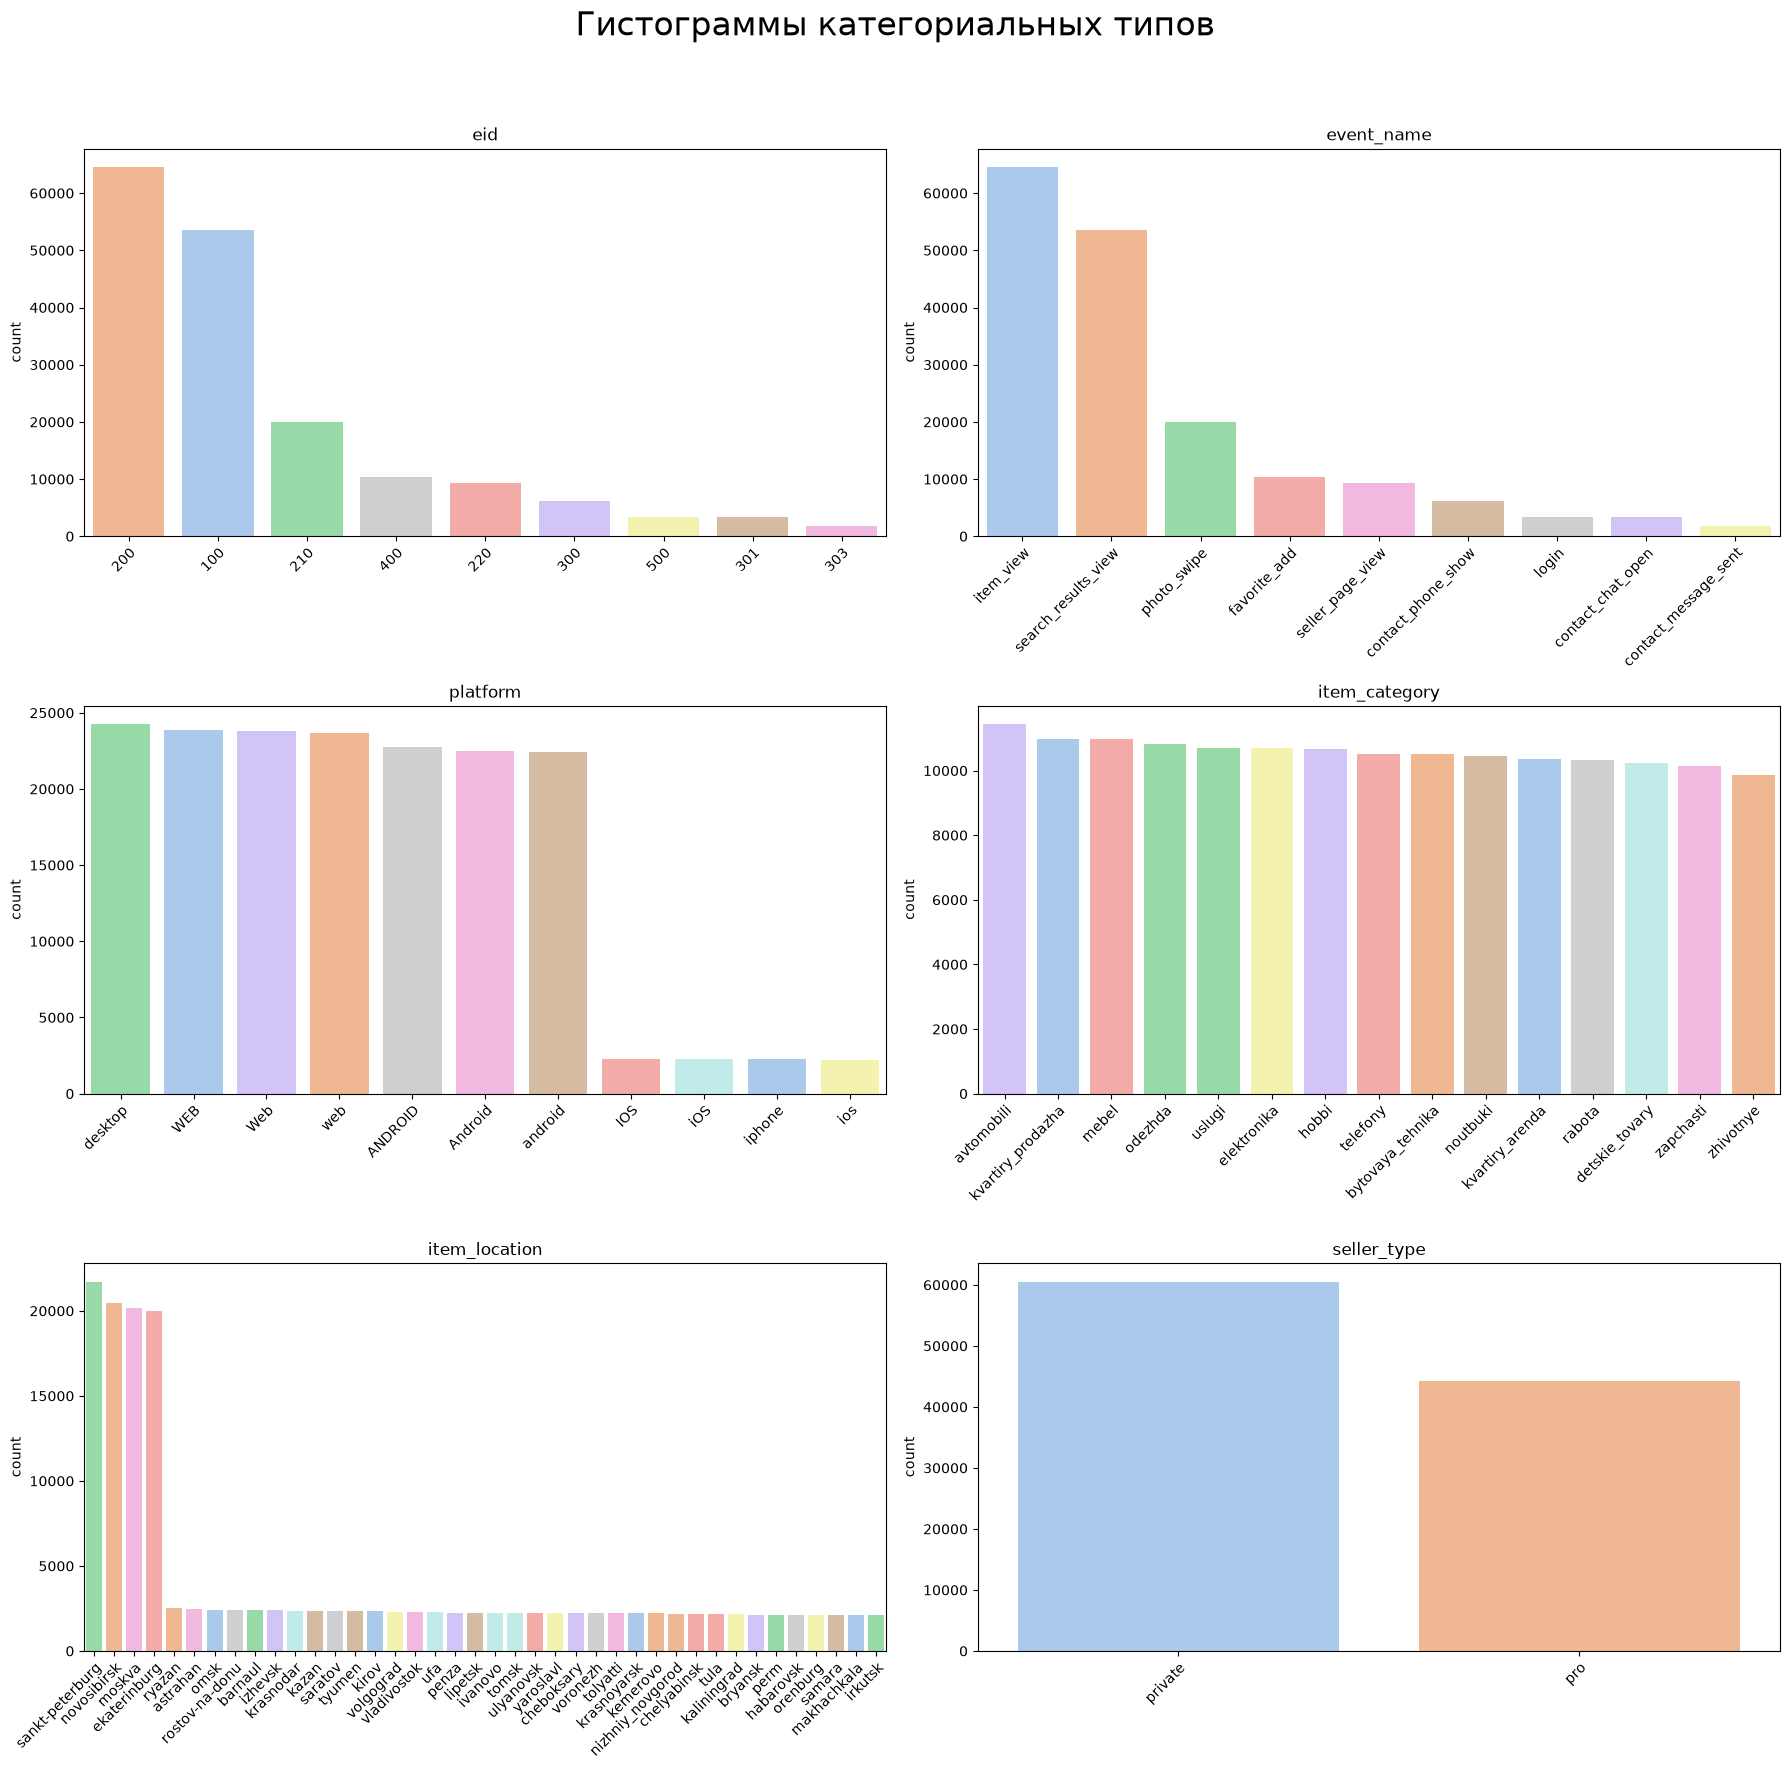

In [1396]:
hyst_categorigal_features = categorical_features.copy()
hyst_categorigal_features.remove("user_agent")  # уже обработано
hyst_categorigal_features.remove("search_query")  # уже обработано
hyst_categorigal_features.remove("cookie_id")  # слишком много уникальных значений
hyst_categorigal_features.remove("item_id")  # слишком много уникальных значений

cols = 2
rows = math.ceil(len(hyst_categorigal_features) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 9, rows * 6))
axes = axes.flatten()


for i, col in enumerate(hyst_categorigal_features):
    ax = axes[i]
    order = events_train[col].value_counts().index  # Чтобы порядок был по убыванию
    counts = events_train[col].value_counts()
    total = len(events_train)

    sns.countplot(
        data=events_train,
        x=col,
        hue=col,
        ax=ax,
        order=order,
        palette="pastel",
        legend=False,
    )
    ax.set_title(col)
    ax.set_xlabel("")
    plt.setp(
        ax.get_xticklabels(),
        rotation=45,
        ha="right",
        rotation_mode="anchor",
    )

    ax.set_ylim(0, max(counts.values) * 1.05)

fig.suptitle("Гистограммы категориальных типов", fontsize=24)
fig.tight_layout(rect=[0.0, 0.0, 1.0, 0.95])  # type: ignore
plt.show()

Наблюдения:
1. `eid` и `event_name` кодируют одно и то же, поэтому два одинаковых признака лучше не хранить. По названиям в `event_name` видно, что событий ошибок среди них нет. Можно дополнительно добавить фичу, кодирующую социальное было совершено событие или же поисковое. А `eid` просто удалить.
2. В `platform` видно много одинаковых слов в разных регистрах, также категории `desktop` и `web` выглядят подозрительно, возможно это одна и та же категория. Также можно добавить фичу, отмечающую что устройство это телефон (ios или android).
3. Категории товаров в датасете распределены равномерно, разных имен для одинаковых категорий нет.
4. `item_location` разделяет локации на 4 главных: Санкт-Петербург, Новосибирск, Москва, Екатеринбург и остальные, распределенные равномерно. Можно дополнительно добавить фичу, является ли город отправления "большим". Также можно выяснить, отправлялись ли все запросы лишь по одной локации.
5. Категория `seller_type` бинарная.

In [1397]:
pd.crosstab(events["platform"], events["device_type"])

device_type,desktop,mobile,unknown
platform,,,
ANDROID,0,37013,0
Android,0,36802,0
IOS,0,3589,0
WEB,38342,0,1398
Web,38212,0,1477
android,0,36741,0
desktop,38663,0,1496
iOS,0,3593,0
ios,0,3600,0


Судя по этой таблице, `desktop` и `web` действительно одинаковая категория.

In [1398]:
# предобработка event_name
view_event = ["item_view", "search_results_view", "seller_page_view"]
interaction_event = ["photo_swipe", "favorite_add"]
login_event = ["login"]
view_contacts_event = ["contact_phone_show", "contact_chat_open"]
seller_interaction_event = ["contact_message_sent"]
events["is_view_event"] = events["event_name"].isin(view_event)
events["is_interaction_event"] = events["event_name"].isin(interaction_event)
events["is_login"] = events["event_name"].isin(login_event)
events["is_view_contacts_event"] = events["event_name"].isin(view_contacts_event)
events["is_seller_interaction_event"] = events["event_name"].isin(
    seller_interaction_event
)

# предобработка platform
platform_mapping = {
    "web": "web",
    "desktop": "web",
    "android": "android",
    "ios": "ios",
    "iphone": "ios",
    "ipad": "ios",
}
events["platform"] = (
    events["platform"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace(platform_mapping)
)
for device in ["mobile", "desktop"]:
    events[f"is_login_{device}"] = events["is_login"] & events["device_type"].eq(
        device
    ).fillna(False)
events["is_login_unknown_device"] = events["is_login"] & ~events["device_type"].isin(
    ["mobile", "desktop"]
)
for platform in ["web", "android", "ios"]:
    events[f"is_login_{platform}"] = events["is_login"] & events["platform"].eq(
        platform
    ).fillna(False)

# предобработка item_location
big_cities = ["sankt-peterburg", "novosibirsk", "moskva", "ekaterinburg"]
events["is_big_city"] = events["item_location"].isin(big_cities)

# предобработка seller_type
events["is_pro_seller_event"] = events["seller_type"].eq("pro").fillna(False)
events["is_private_seller_event"] = events["seller_type"].eq("private").fillna(False)

# добавление фичей
cat_features_aggregated = (
    events.groupby("cookie_id")
    .agg(
        event_count=("event_name", "size"),
        view_event_count=("is_view_event", "sum"),
        view_event_share=("is_view_event", "mean"),
        interaction_event_count=("is_interaction_event", "sum"),
        interaction_event_share=("is_interaction_event", "mean"),
        login_count=("is_login", "sum"),
        login_share=("is_login", "mean"),
        view_contacts_count=("is_view_contacts_event", "sum"),
        view_contacts_share=("is_view_contacts_event", "mean"),
        seller_interaction_count=("is_seller_interaction_event", "sum"),
        seller_interaction_share=("is_seller_interaction_event", "mean"),
        mobile_login_count=("is_login_mobile", "sum"),
        desktop_login_count=("is_login_desktop", "sum"),
        unknown_device_login_count=("is_login_unknown_device", "sum"),
        web_login_count=("is_login_web", "sum"),
        web_login_share=("is_login_web", "mean"),
        android_login_count=("is_login_android", "sum"),
        ios_login_count=("is_login_ios", "sum"),
        unique_category_count=("item_category", "nunique"),
        unique_location_count=("item_location", "nunique"),
        big_city_share=("is_big_city", "mean"),
        pro_seller_event_count=("is_pro_seller_event", "sum"),
        private_seller_event_count=("is_private_seller_event", "sum"),
        pro_seller_share=("is_pro_seller_event", "mean"),
    )
    .reindex(features.index)
)

cat_features_aggregated["web_login_pct"] = (
    100.0
    * cat_features_aggregated["web_login_count"]
    / cat_features_aggregated["login_count"].replace(0, np.nan)
)
features[cat_features_aggregated.columns] = cat_features_aggregated

features["viewed_item_count"] = (
    events.loc[events["event_name"].eq("item_view")]
    .groupby("cookie_id")["item_id"]
    .nunique()
    .reindex(features.index, fill_value=0)
)

known_seller_count = (
    features["pro_seller_event_count"] + features["private_seller_event_count"]
)
features["pro_share_among_known_sellers"] = features[
    "pro_seller_event_count"
] / known_seller_count.replace(0, np.nan)

Добавленные признаки:
- смысл всех новых признаков понятен по названию

Добавим еще несколько более интересных признаков.

In [1399]:
# энтропия категорий
category_counts = (
    events.dropna(subset=["item_category"])
    .groupby(["cookie_id", "item_category"])
    .size()
)
category_probabilities = category_counts / category_counts.groupby(
    level="cookie_id"
).transform("sum")
category_entropy = (
    (-(category_probabilities * np.log(category_probabilities)))
    .groupby(level="cookie_id")
    .sum()
)
cat_features_aggregated["category_entropy"] = category_entropy.reindex(
    cat_features_aggregated.index
)

# доля повторных просмотров
item_views = events.loc[
    events["event_name"].eq("item_view") & events["item_id"].notna(),
    ["cookie_id", "item_id"],
]
view_counts = item_views.groupby("cookie_id").size()
viewed_items = item_views.drop_duplicates(subset=["cookie_id", "item_id"])
unique_view_counts = viewed_items.groupby("cookie_id").size()
repeat_view_share = (view_counts - unique_view_counts) / view_counts
cat_features_aggregated["repeat_item_view_share"] = repeat_view_share.reindex(
    cat_features_aggregated.index
)

# доля взаимодействий с продуктом, у которых также было контактное взаимодействие
contact_events = [
    "contact_phone_show",
    "contact_chat_open",
    "contact_message_sent",
]
contacted_items = events.loc[
    events["event_name"].isin(contact_events) & events["item_id"].notna(),
    ["cookie_id", "item_id"],
].drop_duplicates(subset=["cookie_id", "item_id"])
viewed_and_contacted = viewed_items.merge(
    contacted_items,
    on=["cookie_id", "item_id"],
    how="inner",
    validate="one_to_one",
)
contacted_view_counts = (
    viewed_and_contacted.groupby("cookie_id")
    .size()
    .reindex(cat_features_aggregated.index, fill_value=0)
)
viewed_item_counts = unique_view_counts.reindex(
    cat_features_aggregated.index,
    fill_value=0,
)
cat_features_aggregated["contacted_viewed_item_share"] = (
    contacted_view_counts / viewed_item_counts.replace(0, np.nan)
)

# добавление новых признаков
features[cat_features_aggregated.columns] = (
      cat_features_aggregated.reindex(features.index)
  )

Добавленные признаки:
- `category_entropy` - энтропия категорий
- `repeat_item_view_share` - доля повторных просмотров
- `contacted_viewed_item_share` - доля взаимодействий с продуктом, у которых также было контактное взаимодействие

### Проверка

Проведем визуальный анализ, так как мы добавили очень много признаков.

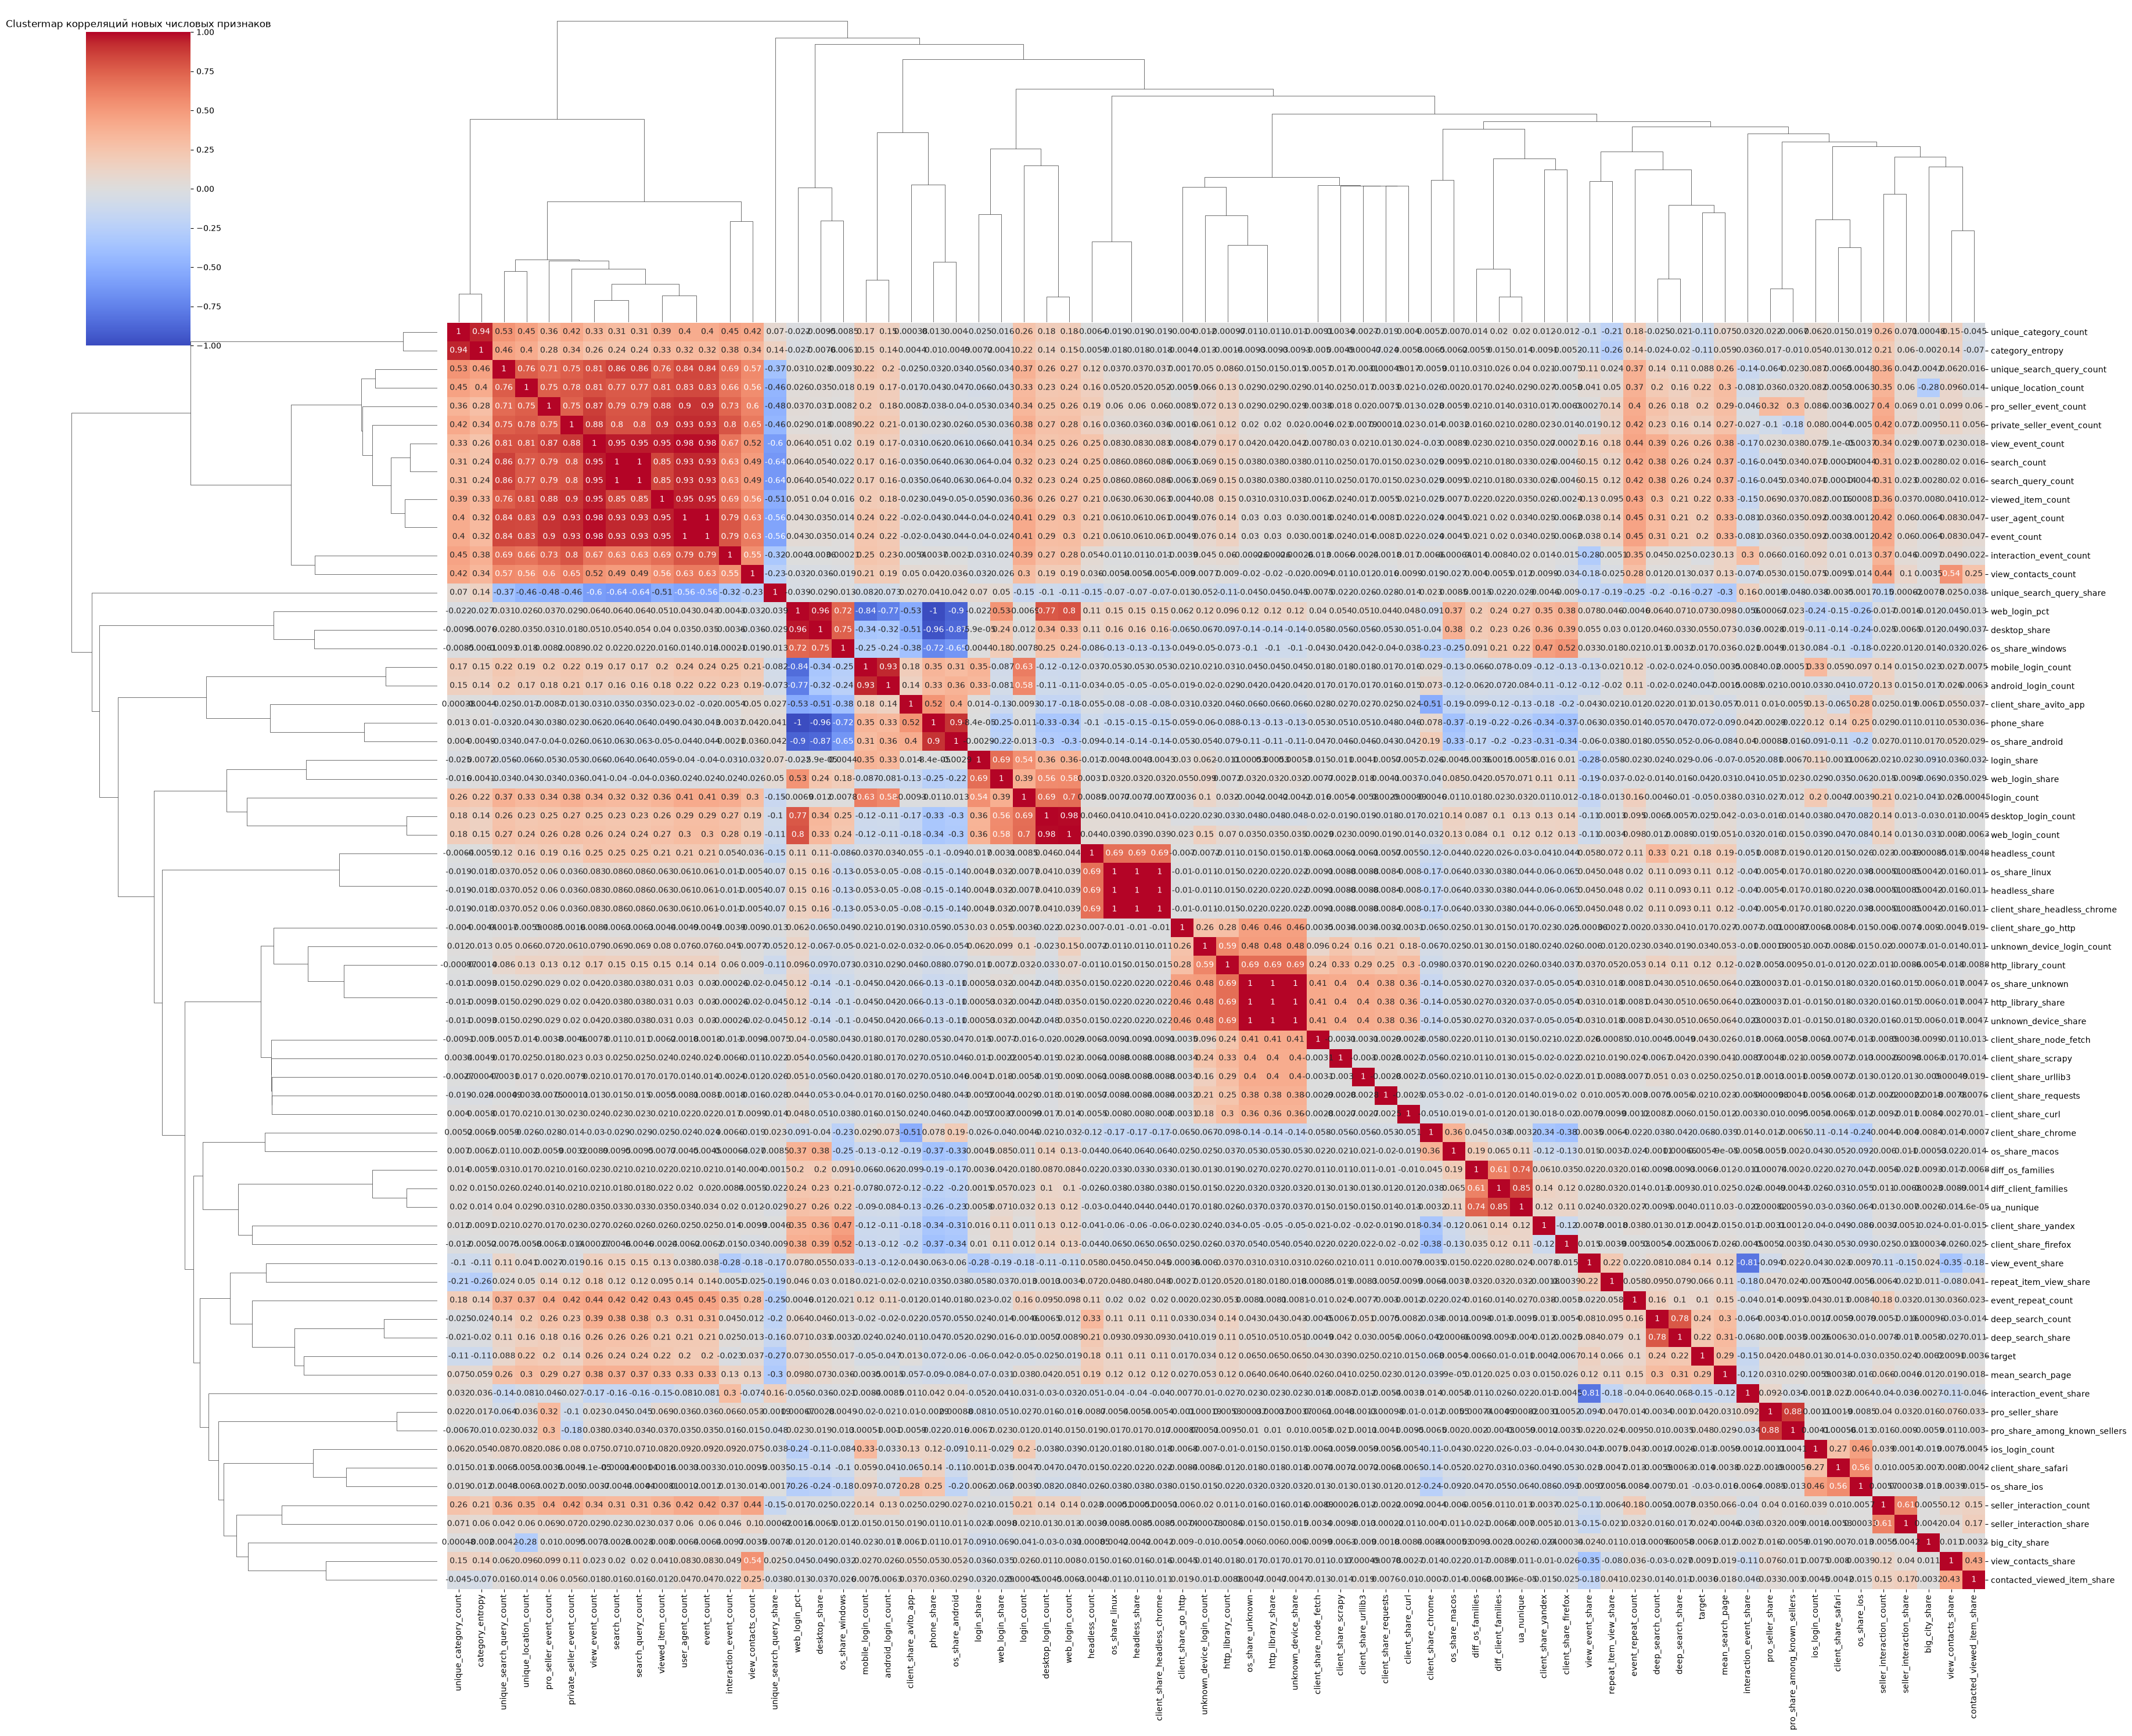

In [1400]:
# Корреляции изучаем только на обучающих датах, без итогового holdout.
analysis_features = features.loc[
    features["dataset"].eq("train")
    & ~features["window_start_ts"].dt.normalize().isin(validation_dates)
]
exclude = [
    "mean_dist_from_zero",
    "min_dist_from_zero",
    "std_x",
    "std_y",
    "mean_x",
    "median_x",
]  # координатные признаки рассматриваются отдельно: некоторые парные корреляции не определены
numeric_cols = analysis_features.select_dtypes(include="number").columns
numeric_cols = numeric_cols[~numeric_cols.isin(exclude)]

sns.clustermap(
    analysis_features[numeric_cols].corr(), cmap="coolwarm", annot=True, figsize=(36, 30)
)
plt.title("Clustermap корреляций новых числовых признаков")
plt.show()

Проанализируем некоторые особенно высокие корреляции:
1. `desktop_login_count` и `web_login_count`. Ранее мы выясняли, что это одно и то же, поэтому `web_login_count` можно удалить. Корреляции этих двоих с другими признаками так же почти равны.
2. `phone_share`, `desktop_share` и `web_login_pct`. `phone_share` и `desctop_share` действительно взаимозаменяемы, но `web_login_pct` не связан с этими показателями. Пока что удалим только `phone_share`.
3. `http_library_share` и `unknown_device_share`. Эти признаки полностью совпадают, поэтому удалим, например, второй.
4. `user_agent_count` и `event_count`. Выше мы убеждались в том, что `user_agent` заполнен без пропусков, поэтому это то же самое, что `event_count`. Удалим `user_agent_count`.
5. `search_count` и `search_query_count`. Одно и то же. Удалим `search_count`.

In [1401]:
features = features.drop(columns=["web_login_count", "phone_share", "user_agent_count", "search_count", "unknown_device_share"])

### Временные признаки

In [1402]:
time_features

['event_ts', 'window_start_ts', 'window_end_ts']

Начало и конец временного окна это метаинформация, из нее можно получить, к примеру день недели. Время события это намного более полезная события, мы можем посмотреть периодичность событий, сосредоточены ли они все в нескольких минутах/секундах, узнать часто ли меняется `user_agent` или тип товара и так далее.

Рассчитаем 11 признаков для каждой куки по событиям внутри её окна:

- `cookie_age_at_window_start_days` — возраст куки к началу окна, в днях
- `first_event_delay_seconds` — время от начала окна до первого события
- `last_event_to_window_end_seconds` — время от последнего события до конца окна
- `activity_span_share` — разница между последним и первым событием, делённая на длину окна
- `gap_median_seconds`, `gap_q10_seconds`, `gap_q90_seconds` — медиана, 10-й и 90-й процентили интервалов между соседними событиями
- `gap_cv` — выборочное стандартное отклонение интервалов, делённое на их среднее
- `same_second_share` — доля соседних пар событий, попавших в одну календарную секунду
- `active_minutes_count` — число календарных минут хотя бы с одним событием
- `events_per_active_minute` — число событий, делённое на число активных минут

In [1403]:
time_events = events[["cookie_id", "event_ts"]].sort_values(
    ["cookie_id", "event_ts"]
).copy()
time_events["gap_seconds"] = (
    time_events.groupby("cookie_id")["event_ts"].diff().dt.total_seconds()
)
time_events["event_second"] = time_events["event_ts"].dt.floor("s")
time_events["event_minute"] = time_events["event_ts"].dt.floor("min")
previous_second = time_events.groupby("cookie_id")["event_second"].shift()
time_events["same_second_as_previous"] = (
    time_events["event_second"]
    .eq(previous_second)
    .astype("boolean")
    .where(previous_second.notna())
)

time_groups = time_events.groupby("cookie_id")
time_summary = time_groups.agg(
    first_event_ts=("event_ts", "min"),
    last_event_ts=("event_ts", "max"),
    observed_event_count=("event_ts", "size"),
    active_minutes_count=("event_minute", "nunique"),
    gap_median_seconds=("gap_seconds", "median"),
    gap_mean_seconds=("gap_seconds", "mean"),
    gap_std_seconds=("gap_seconds", "std"),
    same_second_share=("same_second_as_previous", "mean"),
).reindex(features.index)

window_seconds = (
    features["window_end_ts"] - features["window_start_ts"]
).dt.total_seconds()

time_features_aggregated = pd.DataFrame(index=features.index)
time_features_aggregated["cookie_age_at_window_start_days"] = (
    features["window_start_ts"] - features["cookie_created_at"]
).dt.total_seconds() / 86400

time_features_aggregated["first_event_delay_seconds"] = (
    time_summary["first_event_ts"] - features["window_start_ts"]
).dt.total_seconds()
time_features_aggregated["last_event_to_window_end_seconds"] = (
    features["window_end_ts"] - time_summary["last_event_ts"]
).dt.total_seconds()
time_features_aggregated["activity_span_share"] = (
    (time_summary["last_event_ts"] - time_summary["first_event_ts"])
    .dt.total_seconds()
    / window_seconds.where(window_seconds.gt(0))
)

time_features_aggregated["gap_median_seconds"] = time_summary["gap_median_seconds"]
time_features_aggregated["gap_q10_seconds"] = time_groups["gap_seconds"].quantile(0.1)
time_features_aggregated["gap_q90_seconds"] = time_groups["gap_seconds"].quantile(0.9)
time_features_aggregated["gap_cv"] = (
    time_summary["gap_std_seconds"]
    / time_summary["gap_mean_seconds"].replace(0, np.nan)
)
time_features_aggregated["same_second_share"] = (
    time_summary["same_second_share"].astype("float64")
)
time_features_aggregated["active_minutes_count"] = (
    time_summary["active_minutes_count"].fillna(0).astype("int64")
)
time_features_aggregated["events_per_active_minute"] = (
    time_summary["observed_event_count"]
    / time_features_aggregated["active_minutes_count"].replace(0, np.nan)
)

features[time_features_aggregated.columns] = time_features_aggregated


In [1404]:
features.describe()

,cookie_created_at,window_start_ts,window_end_ts,target,event_repeat_count,deep_search_count,mean_search_page,deep_search_share,mean_dist_from_zero,min_dist_from_zero,...,first_event_delay_seconds,last_event_to_window_end_seconds,activity_span_share,gap_median_seconds,gap_q10_seconds,gap_q90_seconds,gap_cv,same_second_share,active_minutes_count,events_per_active_minute
count,16000,16000,16000,11091.000000,16000.000000,16000.0,14644.000000,14644.0,5861.000000,5861.000000,...,16000.000000,16000.000000,16000.000000,15641.00000,15641.000000,15641.000000,15049.000000,15641.000000,16000.000000,16000.000000
mean,2026-02-02 18:15:52.001812,2026-04-15 13:27:23.400000,2026-04-16 13:27:23.400000,0.081057,0.268313,0.015625,2.445342,0.000709,1153.807307,480.448293,...,46496.724313,28235.318563,0.135046,213.62675,83.472137,2214.124832,2.075423,0.006493,11.494750,1.506634
min,2025-01-15 16:57:05,2026-04-06 00:00:00,2026-04-07 00:00:00,0.000000,0.000000,0.0,1.000000,0.0,143.136299,0.000000,...,3.000000,1.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2025-12-27 15:15:25.500000,2026-04-10 00:00:00,2026-04-11 00:00:00,0.000000,0.000000,0.0,1.500000,0.0,1058.457882,242.043385,...,27995.500000,6221.500000,0.020093,34.00000,8.400000,138.800000,1.390547,0.000000,5.000000,1.153846
50%,2026-02-15 02:19:54,2026-04-15 00:00:00,2026-04-16 00:00:00,0.000000,0.000000,0.0,2.166667,0.0,1170.181738,409.205327,...,47847.500000,23614.500000,0.097078,57.50000,16.000000,1456.500000,2.080892,0.000000,9.000000,1.333333
75%,2026-04-03 19:28:54.250000,2026-04-21 00:00:00,2026-04-22 00:00:00,0.000000,0.000000,0.0,3.000000,0.0,1269.435084,643.795775,...,67537.250000,45870.500000,0.192746,99.00000,31.400000,3900.500000,2.665531,0.000000,15.000000,1.625000
max,2026-04-25 23:00:54,2026-04-26 00:00:00,2026-04-27 00:00:00,1.000000,6.000000,7.0,15.000000,0.25,2062.849486,2062.849486,...,86389.000000,85947.000000,0.966296,9005.00000,9005.000000,9005.000000,10.801188,1.000000,90.000000,13.500000
std,NaN,NaN,NaN,0.272934,0.583817,0.19367,1.268719,0.008104,210.817630,323.580425,...,23920.773919,23308.515036,0.142753,743.92906,492.817550,2297.695141,0.999620,0.036475,9.806916,0.725956


## Разделение на выборки

Даты, изначально выделенные в `events_validation`, исключаем из `X` и `y` и сохраняем отдельно в `X_holdout`, `y_holdout`.

In [1405]:
labeled_features = features.loc[features["dataset"].eq("train")]
holdout_dates = pd.DatetimeIndex(validation_dates).normalize().sort_values()
is_holdout = labeled_features["window_start_ts"].dt.normalize().isin(holdout_dates)
train_features = labeled_features.loc[~is_holdout].copy()
holdout_features = labeled_features.loc[is_holdout].copy()

feature_columns = (
    train_features.select_dtypes(include=["number", "bool"])
    .columns.drop("target")
    .tolist()
)
X = train_features[feature_columns].astype(float)
y = train_features["target"].astype(int)
X_holdout = holdout_features[feature_columns].astype(float)
y_holdout = holdout_features["target"].astype(int)

cookie_dates = train_features["window_start_ts"].dt.normalize()
dates = np.sort(cookie_dates.unique())

tsc = TimeSeriesSplit(n_splits=4, test_size=2)
folds = []

for fold, (train_date_idx, valid_date_idx) in enumerate(
    tsc.split(dates), start=1
):
    train_dates = dates[train_date_idx]
    valid_dates = dates[valid_date_idx]
    train_ids = X.index[cookie_dates.isin(train_dates)]
    valid_ids = X.index[cookie_dates.isin(valid_dates)]

    folds.append((train_ids, valid_ids))

    print(
        f"Фолд {fold}: "
        f"train {pd.Timestamp(train_dates.min()):%d.%m}"
        f"–{pd.Timestamp(train_dates.max()):%d.%m}, {len(train_ids)} кук; "
        f"valid {pd.Timestamp(valid_dates.min()):%d.%m}"
        f"–{pd.Timestamp(valid_dates.max()):%d.%m}, {len(valid_ids)} кук"
    )
print(
    f"Итоговый holdout: {holdout_dates.min():%d.%m}–{holdout_dates.max():%d.%m}, "
    f"{len(X_holdout)} кук; исключён из X, y и всех фолдов подбора"
)

Фолд 1: train 06.04–09.04, 3305 кук; valid 10.04–11.04, 1808 кук
Фолд 2: train 06.04–11.04, 5113 кук; valid 12.04–13.04, 1660 кук
Фолд 3: train 06.04–13.04, 6773 кук; valid 14.04–15.04, 1627 кук
Фолд 4: train 06.04–15.04, 8400 кук; valid 16.04–17.04, 1453 кук
Итоговый holdout: 18.04–19.04, 1238 кук; исключён из X, y и всех фолдов подбора


Посмотрим, как меняется доля положительного класса в последовательных временных фолдах. `TimeSeriesSplit` разделяет данные по датам без стратификации по `target`, поэтому состав train и validation может различаться.

,train_dates,train_cookies,train_bots,train_bot_share_pct,valid_dates,valid_cookies,valid_bots,valid_bot_share_pct,valid_minus_train_pp
fold,,,,,,,,,
1,06.04–09.04,3305,263,7.96,10.04–11.04,1808,161,8.90,0.95
2,06.04–11.04,5113,424,8.29,12.04–13.04,1660,120,7.23,-1.06
3,06.04–13.04,6773,544,8.03,14.04–15.04,1627,135,8.30,0.27
4,06.04–15.04,8400,679,8.08,16.04–17.04,1453,126,8.67,0.59


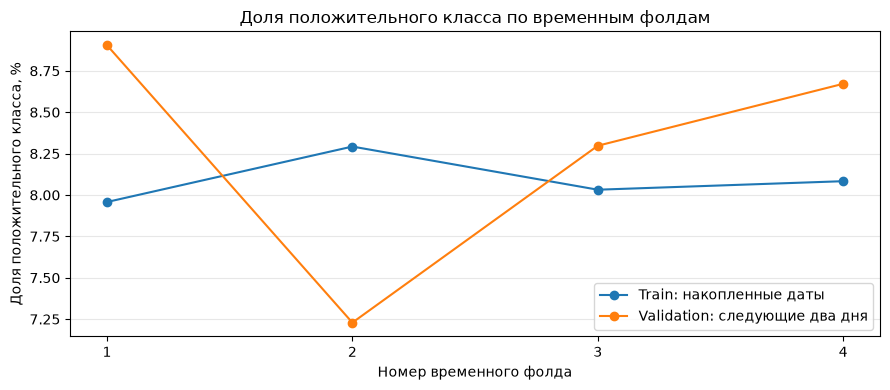

In [1406]:
fold_target_rows = []
for fold, (train_ids, valid_ids) in enumerate(folds, start=1):
    train_target = y.loc[train_ids]
    valid_target = y.loc[valid_ids]
    train_dates = cookie_dates.loc[train_ids]
    valid_dates = cookie_dates.loc[valid_ids]

    fold_target_rows.append(
        {
            "fold": fold,
            "train_dates": (
                f"{train_dates.min():%d.%m}–{train_dates.max():%d.%m}"
            ),
            "train_cookies": len(train_target),
            "train_bots": int(train_target.sum()),
            "train_bot_share_pct": 100 * train_target.mean(),
            "valid_dates": (
                f"{valid_dates.min():%d.%m}–{valid_dates.max():%d.%m}"
            ),
            "valid_cookies": len(valid_target),
            "valid_bots": int(valid_target.sum()),
            "valid_bot_share_pct": 100 * valid_target.mean(),
            "valid_minus_train_pp": 100 * (valid_target.mean() - train_target.mean()),
        }
    )

fold_target_stats = pd.DataFrame(fold_target_rows).set_index("fold")
display(fold_target_stats.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(
    fold_target_stats.index,
    fold_target_stats["train_bot_share_pct"],
    marker="o",
    label="Train: накопленные даты",
)
ax.plot(
    fold_target_stats.index,
    fold_target_stats["valid_bot_share_pct"],
    marker="o",
    label="Validation: следующие два дня",
)
ax.set_xticks(fold_target_stats.index)
ax.set_xlabel("Номер временного фолда")
ax.set_ylabel("Доля положительного класса, %")
ax.set_title("Доля положительного класса по временным фолдам")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


## Выбор моделей

1. Для оценки пользы генерации признаков сравним две логистические регрессии: на двух простых счетчиках и на полном наборе признаков. Модель и временные фолды у них будут одинаковыми. Для логистической регрессии заполним пропуски медианой и масштабируем признаки внутри каждого обучающего фолда.
2. Средним вариантом будет встроенная в `scikit-learn` модель `HistGradientBoostingClassifier`.
3. В качестве серьезных кандидатов, подберем несколько лучших моделей из индустрии. Первым вариантом будет `CatBoostClassifier`. Для этой модели дополнительная обработка данных не потребуется.
4. Вторым вариантом будет `LGBMClassifier`.
5. Также попробуем `XGBoost` с разными стратегиями.

In [1407]:
# гиперпараметры
hist_gradient_boosting_hyperparams = {
    'loss': 'log_loss',
    "learning_rate": 0.05,
    'max_iter': 200,
    'l2_regularization': 5.0,
    'early_stopping': False, # фиксируем длительность обучения на всех фолдах
    'random_state': 3339,
}
catboost_hyperparams = {
    'l2_leaf_reg': 5.0,
    'verbose': False,
    'allow_writing_files': False,
    'random_seed': 3339,
}
lgbm_hyperparams = {
    'objective': 'binary',
    'boosting_type': 'gbdt',
    'subsample': 0.8,
    'subsample_freq': 1,
    'colsample_bytree': 0.8,
    'reg_lambda': 5.0,
    'verbosity': -1,
    'random_state': 3339
}
xgb_hyperparams = {
    'objective': 'binary:logistic',
    'booster': 'gbtree',
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'reg_lambda': 5.0,
    'eval_metric': 'logloss',
    'random_state': 3339
}

models = {
      "logistic_regression": make_pipeline(
          SimpleImputer(strategy="median", add_indicator=True),
          StandardScaler(),
          LogisticRegression(),
      ),
      "hist_gradient_boosting": HistGradientBoostingClassifier(**hist_gradient_boosting_hyperparams),
      "catboost": CatBoostClassifier(**catboost_hyperparams),
      "lgbm": LGBMClassifier(**lgbm_hyperparams),
      "xgboost": XGBClassifier(**xgb_hyperparams),
  }

Сначала обучим все выбранные модели на полном наборе признаков.

In [1408]:
def models_experiment(model_candidates=None, show_tables=True, feature_matrix=None):
    """Оценить модели на тех же временных фолдах и вернуть метрики."""
    if model_candidates is None:
        model_candidates = models
    experiment_X = X if feature_matrix is None else feature_matrix
    results = []

    for model_name, estimator in model_candidates.items():
        for fold, (train_ids, valid_ids) in enumerate(folds, start=1):
            model = clone(estimator)

            model.fit(
                experiment_X.loc[train_ids],
                y.loc[train_ids],
            )

            train_score = model.predict_proba(experiment_X.loc[train_ids])[:, 1]
            valid_score = model.predict_proba(experiment_X.loc[valid_ids])[:, 1]

            train_metric = precision_at_recall(
                y.loc[train_ids],
                train_score,
                recall=0.70,
            )

            score = precision_at_recall(
                y.loc[valid_ids],
                valid_score,
                recall=0.70,
            )

            results.append(
                {
                    "model": model_name,
                    "fold": fold,
                    "precision_at_recall": score,
                    "train_precision_at_recall": train_metric,
                }
            )

    results = pd.DataFrame(results)

    if show_tables:
        scores_by_fold = results.pivot(
            index="model",
            columns="fold",
            values="precision_at_recall",
        )

        summary = (
            results.groupby("model")["precision_at_recall"]
            .agg(["mean", "std", "min"])
            .sort_values("mean", ascending=False)
        )

        train_scores_by_fold = results.pivot(
            index="model",
            columns="fold",
            values="train_precision_at_recall",
        )

        train_summary = (
            results.groupby("model")["train_precision_at_recall"]
            .agg(["mean", "std", "min"])
            .sort_values("mean", ascending=False)
        )

        print("Validation: метрика по фолдам")
        display(scores_by_fold)
        print("Validation: сводная статистика")
        display(summary)

        print("Train: метрика по фолдам")
        display(train_scores_by_fold)
        print("Train: сводная статистика")
        display(train_summary)

    return results


baseline_results = models_experiment()

Validation: метрика по фолдам


fold,1,2,3,4
model,,,,
catboost,0.624309,0.700000,0.714286,0.684615
hist_gradient_boosting,0.680723,0.694215,0.730769,0.689922
lgbm,0.666667,0.700000,0.698529,0.679389
logistic_regression,0.511312,0.549020,0.539773,0.497207
xgboost,0.710692,0.730435,0.678571,0.674242


Validation: сводная статистика


,mean,std,min
model,,,
hist_gradient_boosting,0.698907,0.021974,0.680723
xgboost,0.698485,0.026796,0.674242
lgbm,0.686146,0.016025,0.666667
catboost,0.680803,0.039563,0.624309
logistic_regression,0.524328,0.024174,0.497207


Train: метрика по фолдам


fold,1,2,3,4
model,,,,
catboost,1.000000,1.000000,1.000000,1.000000
hist_gradient_boosting,1.000000,1.000000,1.000000,1.000000
lgbm,1.000000,1.000000,1.000000,1.000000
logistic_regression,0.570552,0.559322,0.572072,0.580488
xgboost,1.000000,1.000000,1.000000,1.000000


Train: сводная статистика


,mean,std,min
model,,,
catboost,1.000000,0.000000,1.000000
hist_gradient_boosting,1.000000,0.000000,1.000000
lgbm,1.000000,0.000000,1.000000
xgboost,1.000000,0.000000,1.000000
logistic_regression,0.570609,0.008701,0.559322


### Бейзлайн на простых признаках

Используем два счётчика: `event_count` — число событий куки внутри окна, и `viewed_item_count` — число разных объявлений, для которых было событие `item_view`. Это простые агрегации без разбора User-Agent, поисковых запросов, последовательностей и временных интервалов. Оба признака входят в полный набор `X`, поэтому сравнение с логистической регрессией на всех признаках показывает эффект добавленных признаков при неизменной модели.

In [1409]:
basic_feature_columns = ["event_count", "viewed_item_count"]
X_basic = X[basic_feature_columns].copy()

basic_logistic_results = models_experiment(
    {"basic_features": models["logistic_regression"]},
    show_tables=False,
    feature_matrix=X_basic,
)
full_logistic_results = baseline_results.loc[
    baseline_results["model"].eq("logistic_regression")
].copy()
full_logistic_results["model"] = "full_features"
logistic_feature_comparison = pd.concat(
    [basic_logistic_results, full_logistic_results], ignore_index=True
)

validation_by_fold = logistic_feature_comparison.pivot(
    index="fold", columns="model", values="precision_at_recall"
).rename_axis(columns=None)
validation_by_fold["full_minus_basic"] = (
    validation_by_fold["full_features"] - validation_by_fold["basic_features"]
)
print("Validation: сравнение логистических регрессий по фолдам")
display(validation_by_fold.round(4))

logistic_summary = logistic_feature_comparison.groupby("model").agg(
    valid_mean=("precision_at_recall", "mean"),
    valid_std=("precision_at_recall", "std"),
    valid_min=("precision_at_recall", "min"),
    train_mean=("train_precision_at_recall", "mean"),
)
logistic_summary["train_valid_gap"] = (
    logistic_summary["train_mean"] - logistic_summary["valid_mean"]
)
print("Сводка по фолдам подбора")
display(logistic_summary.round(4))

Validation: сравнение логистических регрессий по фолдам


,basic_features,full_features,full_minus_basic
fold,,,
1,0.1300,0.5113,0.3813
2,0.1365,0.5490,0.4125
3,0.1185,0.5398,0.4213
4,0.1380,0.4972,0.3592


Сводка по фолдам подбора


,valid_mean,valid_std,valid_min,train_mean,train_valid_gap
model,,,,,
basic_features,0.1307,0.0089,0.1185,0.1217,-0.0091
full_features,0.5243,0.0242,0.4972,0.5706,0.0463


1. На двух простых счётчиках логистическая регрессия получила среднее значение целевой метрики около **0.13**, а на полном наборе признаков — **0.53**. Улучшение есть на каждом из четырех временных фолдов. Фичи были сгенерированы не впустую.
2. Бустинги превосходят логистическую регрессию даже на полном наборе признаков. В среднем лучшим оказался `hist_gradient_boosting`. Лучший показатель по `std` оказался у `lgbm`. `catboost` показал хорошие результаты на последнем фолде.
3. Околоединичные метрики бустингов на обучающих выборках указывают на возможное переобучение. Попробуем ограничить сложность этих моделей.

In [1410]:
models["catboost"].set_params(depth=5)
models["lgbm"].set_params(max_depth=5)
models["xgboost"].set_params(max_depth=5)
models["hist_gradient_boosting"].set_params(max_depth=5)

depth_results = models_experiment()

Validation: метрика по фолдам


fold,1,2,3,4
model,,,,
catboost,0.631285,0.682927,0.716418,0.654412
hist_gradient_boosting,0.664706,0.700000,0.698529,0.687023
lgbm,0.682635,0.661417,0.778689,0.700787
logistic_regression,0.511312,0.549020,0.539773,0.497207
xgboost,0.714286,0.705882,0.678571,0.609589


Validation: сводная статистика


,mean,std,min
model,,,
lgbm,0.705882,0.051135,0.661417
hist_gradient_boosting,0.687565,0.016306,0.664706
xgboost,0.677082,0.047508,0.609589
catboost,0.671260,0.036775,0.631285
logistic_regression,0.524328,0.024174,0.497207


Train: метрика по фолдам


fold,1,2,3,4
model,,,,
catboost,1.000000,1.000000,1.000000,0.997934
hist_gradient_boosting,0.994975,0.990066,0.967822,0.964072
lgbm,0.995261,0.996689,0.989691,0.975460
logistic_regression,0.570552,0.559322,0.572072,0.580488
xgboost,1.000000,1.000000,1.000000,1.000000


Train: сводная статистика


,mean,std,min
model,,,
xgboost,1.000000,0.000000,1.000000
catboost,0.999483,0.001033,0.997934
lgbm,0.989275,0.009692,0.975460
hist_gradient_boosting,0.979234,0.015548,0.964072
logistic_regression,0.570609,0.008701,0.559322


Уровень обучения на тренировочной выборке немного упал. По всем параметрам снова лидируют `lightgbm` и `hist_gradient_boosting`, поэтому проведем дальнейшее варьирование гиперпараметров на этих моделях.

In [1411]:
# стабилизируем модели
models["lgbm"].set_params(max_depth=-1)
hist_gradient_boosting_hyperparams["max_depth"] = 5
xgb_hyperparams["max_depth"] = 5
catboost_hyperparams["depth"] = 5

In [1412]:
hgb_learning_rates = [0.02, 0.05, 0.1, 0.2, 0.3, 0.5]
hgb_max_leaves_nodes = [7, 15, 31, 63]
hgb_max_depth = [4, 5, 6, 7]
hgb_min_samples_leaves = [10, 20, 30]
hgb_l2_regularization = [1.0, 3.0, 5.0, 10.0, 20.0]
hgb_max_iter = [100, 200, 400, 700]
hgb_max_features = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

lgbm_boosting_types = ['gbdt', 'dart', 'rf']
lgbm_num_leaves = [7, 15, 31, 63]
lgbm_max_depths = [-1, 5, 6, 7]
lgbm_learning_rates = [0.02, 0.05, 0.1, 0.2, 0.3, 0.5]
lgbm_n_estimators = [100, 200, 300, 400, 500]
lgbm_reg_lambdas = [1, 3, 5, 10, 20]
lgbm_min_child_samples = [10, 20, 40, 80]
lgbm_colsamples_bytree = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

### Независимое варьирование гиперпараметров

In [1413]:
hgb_base = clone(models["hist_gradient_boosting"])
lgbm_base = clone(models["lgbm"])

hgb_parameter_values = {
    "learning_rate": hgb_learning_rates,
    "max_leaf_nodes": hgb_max_leaves_nodes,
    "max_depth": hgb_max_depth,
    "min_samples_leaf": hgb_min_samples_leaves,
    "l2_regularization": hgb_l2_regularization,
    "max_iter": hgb_max_iter,
    "max_features": hgb_max_features
}

lgbm_parameter_values = {
    "boosting_type": lgbm_boosting_types,
    "num_leaves": lgbm_num_leaves,
    "max_depth": lgbm_max_depths,
    "learning_rate": lgbm_learning_rates,
    "n_estimators": lgbm_n_estimators,
    "reg_lambda": lgbm_reg_lambdas,
    "min_child_samples": lgbm_min_child_samples,
    "colsample_bytree": lgbm_colsamples_bytree,
}


In [1414]:
def hyperparameters_experiment(estimator, parameter_values, model_name=None):
    base_estimator = clone(estimator)
    base_params = base_estimator.get_params(deep=True)
    model_name = model_name or type(base_estimator).__name__

    print(f"{model_name}: оценка базовой конфигурации", flush=True)
    baseline = models_experiment(
        {model_name: base_estimator}, show_tables=False
    )
    baseline_mean = baseline["precision_at_recall"].mean()
    tables = {}
    all_results = []

    for parameter, candidates in parameter_values.items():
        base_value = base_params[parameter]
        values = [base_value]
        for value in candidates:
            if value not in values:
                values.append(value)

        print(
            f"{model_name}: {parameter}, база={base_value!r}, "
            f"новых вариантов={len(values) - 1}",
            flush=True,
        )
        rows = []
        for value in values:
            is_baseline = value == base_value
            if is_baseline:
                fold_results = baseline.copy()
            else:
                candidate = clone(base_estimator).set_params(**{parameter: value})
                fold_results = models_experiment(
                    {model_name: candidate}, show_tables=False
                )

            valid = fold_results["precision_at_recall"]
            train = fold_results["train_precision_at_recall"]
            row = {
                "value": value,
                "is_baseline": is_baseline,
                "valid_mean": valid.mean(),
                "valid_std": valid.std(),
                "valid_min": valid.min(),
                "train_mean": train.mean(),
                "train_std": train.std(),
                "train_min": train.min(),
                "gap": train.mean() - valid.mean(),
                "delta_valid_mean": valid.mean() - baseline_mean,
            }
            for result in fold_results.itertuples(index=False):
                row[f"valid_fold_{result.fold}"] = result.precision_at_recall
                row[f"train_fold_{result.fold}"] = result.train_precision_at_recall
            rows.append(row)
            all_results.append(
                fold_results.assign(
                    parameter=parameter,
                    value=value,
                    is_baseline=is_baseline,
                )
            )

        table = pd.DataFrame(rows).set_index("value")
        tables[parameter] = table
        display(table.round(4))

    return {
        "base_params": base_params,
        "results": pd.concat(all_results, ignore_index=True),
        "tables": tables,
    }


In [1415]:
hgb_experiments = hyperparameters_experiment(
    hgb_base,
    hgb_parameter_values,
    model_name="hist_gradient_boosting",
)

hist_gradient_boosting: оценка базовой конфигурации
hist_gradient_boosting: learning_rate, база=0.05, новых вариантов=5


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
0.05,True,0.6876,0.0163,0.6647,0.9792,0.0155,0.9641,0.2917,0.0000,0.6647,0.9950,0.7000,0.9901,0.6985,0.9678,0.6870,0.9641
0.02,False,0.6514,0.0030,0.6479,0.8645,0.0258,0.8398,0.2131,-0.0362,0.6514,0.8986,0.6512,0.8692,0.6552,0.8504,0.6479,0.8398
0.10,False,0.6943,0.0461,0.6312,1.0000,0.0000,1.0000,0.3057,0.0067,0.6890,1.0000,0.7241,1.0000,0.7328,1.0000,0.6312,1.0000
0.20,False,0.6885,0.0490,0.6384,1.0000,0.0000,1.0000,0.3115,0.0009,0.6384,1.0000,0.7304,1.0000,0.7308,1.0000,0.6544,1.0000
0.30,False,0.6662,0.0511,0.6014,1.0000,0.0000,1.0000,0.3338,-0.0214,0.6608,1.0000,0.6774,1.0000,0.7252,1.0000,0.6014,1.0000
0.50,False,0.6582,0.1017,0.5115,1.0000,0.0000,1.0000,0.3418,-0.0294,0.7019,1.0000,0.7434,1.0000,0.6761,1.0000,0.5115,1.0000


hist_gradient_boosting: max_leaf_nodes, база=31, новых вариантов=3


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
31,True,0.6876,0.0163,0.6647,0.9792,0.0155,0.9641,0.2917,0.0000,0.6647,0.9950,0.7000,0.9901,0.6985,0.9678,0.6870,0.9641
7,False,0.6537,0.0225,0.6269,0.8989,0.0402,0.8702,0.2452,-0.0339,0.6807,0.9585,0.6269,0.8843,0.6597,0.8828,0.6475,0.8702
15,False,0.6939,0.0498,0.6494,0.9720,0.0179,0.9560,0.2781,0.0064,0.6494,0.9951,0.7636,0.9770,0.6934,0.9598,0.6692,0.9560
63,False,0.6910,0.0176,0.6647,0.9816,0.0130,0.9678,0.2906,0.0034,0.6647,0.9950,0.7000,0.9901,0.6985,0.9678,0.7008,0.9734


hist_gradient_boosting: max_depth, база=5, новых вариантов=3


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
5,True,0.6876,0.0163,0.6647,0.9792,0.0155,0.9641,0.2917,0.0000,0.6647,0.9950,0.7000,0.9901,0.6985,0.9678,0.6870,0.9641
4,False,0.6754,0.0226,0.6441,0.9357,0.0313,0.9068,0.2604,-0.0122,0.6441,0.9788,0.6942,0.9369,0.6738,0.9203,0.6894,0.9068
6,False,0.6726,0.0456,0.6087,0.9983,0.0021,0.9958,0.3257,-0.0149,0.6933,1.0000,0.6087,1.0000,0.7143,0.9974,0.6742,0.9958
7,False,0.6778,0.0221,0.6512,0.9995,0.0010,0.9981,0.3217,-0.0097,0.6848,1.0000,0.6512,1.0000,0.7037,1.0000,0.6716,0.9981


... (4 outputs left out)

hist_gradient_boosting: max_iter, база=200, новых вариантов=3


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
200,True,0.6876,0.0163,0.6647,0.9792,0.0155,0.9641,0.2917,0.0000,0.6647,0.9950,0.7000,0.9901,0.6985,0.9678,0.6870,0.9641
100,False,0.6737,0.0418,0.6278,0.8996,0.0329,0.8799,0.2259,-0.0139,0.6278,0.9487,0.7241,0.8872,0.6884,0.8825,0.6544,0.8799
400,False,0.6910,0.0300,0.6667,1.0000,0.0000,1.0000,0.3090,0.0035,0.6975,1.0000,0.6667,1.0000,0.7308,1.0000,0.6692,1.0000
700,False,0.6748,0.0552,0.5973,1.0000,0.0000,1.0000,0.3252,-0.0127,0.6994,1.0000,0.6774,1.0000,0.7252,1.0000,0.5973,1.0000


hist_gradient_boosting: max_features, база=1.0, новых вариантов=5


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
1.0,True,0.6876,0.0163,0.6647,0.9792,0.0155,0.9641,0.2917,0.0000,0.6647,0.9950,0.7000,0.9901,0.6985,0.9678,0.6870,0.9641
0.5,False,0.6928,0.0234,0.6614,0.9762,0.0207,0.9578,0.2834,0.0052,0.6890,1.0000,0.6614,0.9869,0.7143,0.9599,0.7063,0.9578
0.6,False,0.6760,0.0373,0.6343,0.9797,0.0152,0.9598,0.3037,-0.0116,0.6590,0.9951,0.6343,0.9868,0.6906,0.9770,0.7200,0.9598
0.7,False,0.6830,0.0566,0.6043,0.9814,0.0149,0.9675,0.2984,-0.0046,0.6848,0.9952,0.6043,0.9934,0.7364,0.9696,0.7063,0.9675
0.8,False,0.6965,0.0291,0.6570,0.9723,0.0190,0.9559,0.2758,0.0089,0.6570,0.9952,0.7119,0.9806,0.6934,0.9575,0.7236,0.9559
0.9,False,0.6779,0.0447,0.6176,0.9796,0.0177,0.9583,0.3018,-0.0097,0.6845,0.9949,0.6176,0.9934,0.6835,0.9720,0.7258,0.9583


Самый большой прирост в комбинации с небольшим ростом стандартного отклонения дало изменение коэффициента `max_features` на `0.5`. Метрика выросла на всех фолдах, кроме второго, на котором наблюдается просадка ботов в validation. Давайте зафиксируем этот параметр, а остальные снова переберем. 

In [1416]:
hist_gradient_boosting_hyperparams["max_features"] = 0.5

In [1417]:
hgb_refined_base = clone(hgb_base).set_params(max_features=hist_gradient_boosting_hyperparams["max_features"])
hgb_refined_parameter_values = {
    "learning_rate": hgb_learning_rates,
    "max_leaf_nodes": hgb_max_leaves_nodes,
    "max_depth": hgb_max_depth,
    "min_samples_leaf": hgb_min_samples_leaves,
    "l2_regularization": hgb_l2_regularization,
    "max_iter": hgb_max_iter,
}

print(
    "Фиксированные параметры:",
    {
        name: hgb_refined_base.get_params()[name]
        for name in ("max_features",)
    },
)

hgm_refined_experiments = hyperparameters_experiment(
    hgb_refined_base,
    hgb_refined_parameter_values,
    model_name="hgb_refined",
)

Фиксированные параметры: {'max_features': 0.5}
hgb_refined: оценка базовой конфигурации
hgb_refined: learning_rate, база=0.05, новых вариантов=5


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
0.05,True,0.6928,0.0234,0.6614,0.9762,0.0207,0.9578,0.2834,0.0000,0.6890,1.0000,0.6614,0.9869,0.7143,0.9599,0.7063,0.9578
0.02,False,0.6598,0.0285,0.6243,0.8624,0.0189,0.8467,0.2027,-0.0330,0.6243,0.8852,0.6512,0.8710,0.6738,0.8467,0.6899,0.8470
0.10,False,0.6975,0.0555,0.6383,1.0000,0.0000,1.0000,0.3025,0.0048,0.6909,1.0000,0.6885,1.0000,0.7724,1.0000,0.6383,1.0000
0.20,False,0.7043,0.0867,0.6014,1.0000,0.0000,1.0000,0.2957,0.0115,0.7152,1.0000,0.6885,1.0000,0.8120,1.0000,0.6014,1.0000
0.30,False,0.6971,0.0495,0.6312,1.0000,0.0000,1.0000,0.3029,0.0044,0.6890,1.0000,0.7241,1.0000,0.7442,1.0000,0.6312,1.0000
0.50,False,0.6519,0.0801,0.5361,1.0000,0.0000,1.0000,0.3481,-0.0409,0.6609,1.0000,0.7119,1.0000,0.6985,1.0000,0.5361,1.0000


hgb_refined: max_leaf_nodes, база=31, новых вариантов=3


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
31,True,0.6928,0.0234,0.6614,0.9762,0.0207,0.9578,0.2834,0.0000,0.6890,1.0000,0.6614,0.9869,0.7143,0.9599,0.7063,0.9578
7,False,0.6715,0.0394,0.6338,0.8981,0.0338,0.8782,0.2267,-0.0213,0.7019,0.9487,0.6412,0.8817,0.7090,0.8840,0.6338,0.8782
15,False,0.6773,0.0261,0.6494,0.9653,0.0230,0.9427,0.2879,-0.0154,0.6494,0.9951,0.6693,0.9706,0.6786,0.9526,0.7120,0.9427
63,False,0.6928,0.0234,0.6614,0.9762,0.0207,0.9578,0.2834,0.0000,0.6890,1.0000,0.6614,0.9869,0.7143,0.9599,0.7063,0.9578


hgb_refined: max_depth, база=5, новых вариантов=3


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
5,True,0.6928,0.0234,0.6614,0.9762,0.0207,0.9578,0.2834,0.0000,0.6890,1.0000,0.6614,0.9869,0.7143,0.9599,0.7063,0.9578
4,False,0.6777,0.0246,0.6512,0.9277,0.0289,0.9028,0.2500,-0.0151,0.6647,0.9688,0.6512,0.9252,0.6884,0.9028,0.7063,0.9140
6,False,0.6986,0.0349,0.6746,0.9954,0.0053,0.9898,0.2968,0.0059,0.6746,1.0000,0.7500,1.0000,0.6906,0.9898,0.6794,0.9919
7,False,0.6791,0.0428,0.6333,0.9990,0.0020,0.9960,0.3199,-0.0137,0.6333,1.0000,0.6774,1.0000,0.7364,1.0000,0.6692,0.9960


... (2 outputs left out)

hgb_refined: l2_regularization, база=5.0, новых вариантов=4


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
5.0,True,0.6928,0.0234,0.6614,0.9762,0.0207,0.9578,0.2834,0.0000,0.6890,1.0000,0.6614,0.9869,0.7143,0.9599,0.7063,0.9578
1.0,False,0.6928,0.0335,0.6647,0.9934,0.0081,0.9835,0.3005,0.0001,0.6647,1.0000,0.7368,1.0000,0.6690,0.9899,0.7008,0.9835
3.0,False,0.7084,0.0288,0.6786,0.9870,0.0136,0.9716,0.2786,0.0156,0.6890,1.0000,0.7304,0.9967,0.6786,0.9796,0.7355,0.9716
10.0,False,0.7152,0.0250,0.6899,0.9627,0.0225,0.9444,0.2475,0.0224,0.6975,0.9948,0.7368,0.9613,0.7364,0.9504,0.6899,0.9444
20.0,False,0.6945,0.0378,0.6457,0.9296,0.0179,0.9120,0.2351,0.0017,0.6457,0.9466,0.7059,0.9434,0.7364,0.9163,0.6899,0.9120


hgb_refined: max_iter, база=200, новых вариантов=3


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
200,True,0.6928,0.0234,0.6614,0.9762,0.0207,0.9578,0.2834,0.0000,0.6890,1.0000,0.6614,0.9869,0.7143,0.9599,0.7063,0.9578
100,False,0.6675,0.0498,0.5944,0.8957,0.0337,0.8655,0.2282,-0.0252,0.6807,0.9439,0.5944,0.8892,0.7050,0.8843,0.6899,0.8655
400,False,0.7030,0.0287,0.6614,1.0000,0.0000,1.0000,0.2970,0.0102,0.7244,1.0000,0.6614,1.0000,0.7197,1.0000,0.7063,1.0000
700,False,0.7189,0.0631,0.6614,1.0000,0.0000,1.0000,0.2811,0.0261,0.7244,1.0000,0.6614,1.0000,0.8051,1.0000,0.6846,1.0000


Новый прирост модель показала на ограничении `min_samples_leaf` на значение 30. Также это значение сильно снизило стандартное отклонение на валидационной выборке.

Зафиксируем эти два параметра и перейдем к следующей модели.

In [1418]:
hist_gradient_boosting_hyperparams["min_samples_leaf"] = 30

In [1419]:
lgbm_experiments = hyperparameters_experiment(
    lgbm_base,
    lgbm_parameter_values,
    model_name="lgbm",
)

lgbm: оценка базовой конфигурации
lgbm: boosting_type, база='gbdt', новых вариантов=2


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
gbdt,True,0.6861,0.0160,0.6667,1.0000,0.0000,1.0000,0.3139,0.0000,0.6667,1.0000,0.700,1.0000,0.6985,1.0000,0.6794,1.0000
dart,False,0.6807,0.0172,0.6706,0.9679,0.0054,0.9616,0.2873,-0.0055,0.6706,0.9747,0.672,0.9684,0.6738,0.9670,0.7063,0.9616
rf,False,0.5064,0.0540,0.4484,0.7040,0.0242,0.6752,0.1976,-0.1797,0.4484,0.6752,0.549,0.7005,0.4726,0.7341,0.5556,0.7062


lgbm: num_leaves, база=31, новых вариантов=3


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
31,True,0.6861,0.0160,0.6667,1.0000,0.0000,1.0000,0.3139,0.0000,0.6667,1.0000,0.7000,1.0000,0.6985,1.0000,0.6794,1.0000
7,False,0.6363,0.0670,0.5736,0.9012,0.0334,0.8759,0.2649,-0.0498,0.5736,0.9487,0.5833,0.9000,0.6985,0.8759,0.6899,0.8803
15,False,0.7130,0.0246,0.6909,0.9900,0.0097,0.9814,0.2770,0.0268,0.6909,1.0000,0.6942,0.9967,0.7252,0.9820,0.7417,0.9814
63,False,0.6778,0.0188,0.6615,1.0000,0.0000,1.0000,0.3222,-0.0083,0.6667,1.0000,0.6615,1.0000,0.7037,1.0000,0.6794,1.0000


lgbm: max_depth, база=-1, новых вариантов=3


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
-1,True,0.6861,0.0160,0.6667,1.0000,0.0000,1.0000,0.3139,0.0000,0.6667,1.0000,0.7000,1.0000,0.6985,1.0000,0.6794,1.0000
5,False,0.7059,0.0511,0.6614,0.9893,0.0097,0.9755,0.2834,0.0197,0.6826,0.9953,0.6614,0.9967,0.7787,0.9897,0.7008,0.9755
6,False,0.7022,0.0267,0.6829,0.9972,0.0033,0.9938,0.2949,0.0161,0.6909,1.0000,0.6829,1.0000,0.6934,0.9948,0.7417,0.9938
7,False,0.7113,0.0121,0.7000,0.9990,0.0019,0.9961,0.2877,0.0251,0.7019,1.0000,0.7000,1.0000,0.7197,1.0000,0.7236,0.9961


... (6 outputs left out)

lgbm: min_child_samples, база=20, новых вариантов=3


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
20,True,0.6861,0.0160,0.6667,1.0000,0.0000,1.0000,0.3139,0.0000,0.6667,1.000,0.7000,1.0000,0.6985,1.0000,0.6794,1.0000
10,False,0.7287,0.0582,0.6726,0.9995,0.0010,0.9981,0.2709,0.0425,0.6726,1.000,0.7850,1.0000,0.7724,1.0000,0.6846,0.9981
40,False,0.6681,0.0302,0.6400,0.9995,0.0009,0.9981,0.3314,-0.0180,0.6726,1.000,0.6512,1.0000,0.6400,1.0000,0.7087,0.9981
80,False,0.6737,0.0443,0.6096,0.9963,0.0011,0.9950,0.3226,-0.0125,0.6786,0.995,0.7059,0.9968,0.7007,0.9974,0.6096,0.9958


lgbm: colsample_bytree, база=0.8, новых вариантов=5


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
0.8,True,0.6861,0.0160,0.6667,1.0000,0.000,1.0000,0.3139,0.0000,0.6667,1.0,0.7000,1.0,0.6985,1.0,0.6794,1.0000
0.5,False,0.6800,0.0306,0.6614,0.9995,0.001,0.9979,0.3194,-0.0061,0.6686,1.0,0.6614,1.0,0.6643,1.0,0.7258,0.9979
0.6,False,0.7004,0.0492,0.6312,0.9995,0.001,0.9980,0.2991,0.0143,0.7019,1.0,0.7434,1.0,0.7252,1.0,0.6312,0.9980
0.7,False,0.6889,0.0368,0.6643,0.9995,0.001,0.9980,0.3106,0.0028,0.6686,1.0,0.7434,1.0,0.6643,1.0,0.6794,0.9980
0.9,False,0.6783,0.0448,0.6223,1.0000,0.000,1.0000,0.3217,-0.0078,0.6223,1.0,0.6885,1.0,0.7308,1.0,0.6716,1.0000
1.0,False,0.6969,0.0168,0.6794,1.0000,0.000,1.0000,0.3031,0.0108,0.7019,1.0,0.7179,1.0,0.6884,1.0,0.6794,1.0000


На эту модель лучше всего повлияло снижение `reg_lambda` до `3.0`. Зафиксируем это и поступим с этой моделью аналогично.

In [1420]:
lgbm_hyperparams["reg_lambda"] = 3.0

In [1421]:
lgbm_refined_base = clone(lgbm_base).set_params(reg_lambda=lgbm_hyperparams["reg_lambda"])
lgbm_refined_parameter_values = {
    "boosting_type": lgbm_boosting_types,
    "max_depth": lgbm_max_depths,
    "learning_rate": lgbm_learning_rates,
    "n_estimators": lgbm_n_estimators,
    "reg_lambda": lgbm_reg_lambdas,
    "min_child_samples": lgbm_min_child_samples,
    "colsample_bytree": lgbm_colsamples_bytree,
    "num_leaves": lgbm_num_leaves
}

print(
    "Фиксированные параметры:",
    {
        name: lgbm_refined_base.get_params()[name]
        for name in ("reg_lambda",)
    },
)

lgbm_refined_experiments = hyperparameters_experiment(
    lgbm_refined_base,
    lgbm_refined_parameter_values,
    model_name="lgbm_refined",
)

Фиксированные параметры: {'reg_lambda': 3.0}
lgbm_refined: оценка базовой конфигурации
lgbm_refined: boosting_type, база='gbdt', новых вариантов=2


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
gbdt,True,0.7203,0.0219,0.6909,1.0000,0.0000,1.0000,0.2797,0.0000,0.6909,1.0000,0.7179,1.0000,0.7308,1.0000,0.7417,1.0000
dart,False,0.6641,0.0238,0.6420,0.9830,0.0079,0.9780,0.3189,-0.0562,0.6420,0.9947,0.6614,0.9780,0.6552,0.9798,0.6977,0.9795
rf,False,0.4960,0.0309,0.4538,0.7254,0.0154,0.7061,0.2293,-0.2243,0.4538,0.7061,0.5185,0.7215,0.4922,0.7422,0.5196,0.7316


lgbm_refined: max_depth, база=-1, новых вариантов=3


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
-1,True,0.7203,0.0219,0.6909,1.0000,0.0000,1.0000,0.2797,0.0000,0.6909,1.0,0.7179,1.0000,0.7308,1.0000,0.7417,1.0000
5,False,0.6889,0.0438,0.6269,0.9930,0.0064,0.9875,0.3041,-0.0315,0.6890,1.0,0.6269,0.9968,0.7218,0.9875,0.7177,0.9876
6,False,0.6685,0.0359,0.6222,0.9989,0.0013,0.9974,0.3303,-0.0518,0.6647,1.0,0.6222,1.0000,0.6786,0.9974,0.7087,0.9981
7,False,0.7038,0.0259,0.6807,0.9995,0.0009,0.9982,0.2957,-0.0165,0.6807,1.0,0.7368,1.0000,0.6857,1.0000,0.7120,0.9982


lgbm_refined: learning_rate, база=0.1, новых вариантов=5


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
0.10,True,0.7203,0.0219,0.6909,1.0000,0.0000,1.0000,0.2797,0.0000,0.6909,1.0000,0.7179,1.0000,0.7308,1.0000,0.7417,1.0000
0.02,False,0.6559,0.0295,0.6141,0.8870,0.0089,0.8787,0.2311,-0.0645,0.6141,0.8995,0.6829,0.8787,0.6597,0.8843,0.6667,0.8854
0.05,False,0.6710,0.0216,0.6420,0.9914,0.0086,0.9796,0.3204,-0.0494,0.6420,1.0000,0.6942,0.9937,0.6761,0.9922,0.6715,0.9796
0.20,False,0.6570,0.0196,0.6312,1.0000,0.0000,1.0000,0.3430,-0.0633,0.6786,1.0000,0.6562,1.0000,0.6621,1.0000,0.6312,1.0000
0.30,False,0.6764,0.0481,0.6304,1.0000,0.0000,1.0000,0.3236,-0.0440,0.6304,1.0000,0.6667,1.0000,0.7442,1.0000,0.6642,1.0000
0.50,False,0.6397,0.0219,0.6181,1.0000,0.0000,1.0000,0.3603,-0.0806,0.6420,1.0000,0.6296,1.0000,0.6690,1.0000,0.6181,1.0000


... (6 outputs left out)

lgbm_refined: colsample_bytree, база=0.8, новых вариантов=5


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
0.8,True,0.7203,0.0219,0.6909,1.0000,0.0000,1.0000,0.2797,0.0000,0.6909,1.0,0.7179,1.0,0.7308,1.0,0.7417,1.0000
0.5,False,0.6749,0.0304,0.6364,1.0000,0.0000,1.0000,0.3251,-0.0454,0.7107,1.0,0.6364,1.0,0.6783,1.0,0.6742,1.0000
0.6,False,0.7141,0.0262,0.6766,1.0000,0.0000,1.0000,0.2859,-0.0062,0.6766,1.0,0.7368,1.0,0.7252,1.0,0.7177,1.0000
0.7,False,0.7034,0.0232,0.6835,0.9996,0.0009,0.9983,0.2962,-0.0169,0.7152,1.0,0.7304,1.0,0.6835,1.0,0.6846,0.9983
0.9,False,0.7042,0.0211,0.6807,1.0000,0.0000,1.0000,0.2958,-0.0161,0.6807,1.0,0.7241,1.0,0.7197,1.0,0.6923,1.0000
1.0,False,0.7207,0.0188,0.7059,1.0000,0.0000,1.0000,0.2793,0.0004,0.7170,1.0,0.7059,1.0,0.7480,1.0,0.7120,1.0000


lgbm_refined: num_leaves, база=31, новых вариантов=3


,is_baseline,valid_mean,valid_std,valid_min,train_mean,train_std,train_min,gap,delta_valid_mean,valid_fold_1,train_fold_1,valid_fold_2,train_fold_2,valid_fold_3,train_fold_3,valid_fold_4,train_fold_4
value,,,,,,,,,,,,,,,,,
31,True,0.7203,0.0219,0.6909,1.0000,0.0000,1.0000,0.2797,0.0000,0.6909,1.0000,0.7179,1.000,0.7308,1.0000,0.7417,1.0000
7,False,0.6662,0.0761,0.5638,0.9149,0.0333,0.8916,0.2487,-0.0541,0.6746,0.9643,0.5638,0.903,0.6786,0.9007,0.7479,0.8916
15,False,0.6901,0.0413,0.6412,0.9932,0.0072,0.9835,0.3030,-0.0302,0.6706,1.0000,0.6412,0.997,0.7252,0.9922,0.7236,0.9835
63,False,0.6775,0.0221,0.6449,1.0000,0.0000,1.0000,0.3225,-0.0428,0.6933,1.0000,0.6885,1.000,0.6835,1.0000,0.6449,1.0000


Единственный параметр, улучшающий среднюю метрику это `colsample_bytree = 1.0`. Зафиксируем этот параметр и перейдем к валидации.

In [1422]:
lgbm_hyperparams["colsample_bytree"] = 1.0

## Валидация

In [1423]:
catboost_classifier = CatBoostClassifier(**catboost_hyperparams)
xgb_classifier = XGBClassifier(**xgb_hyperparams)

hgb_first_param_classifier = clone(hgb_base).set_params(
    max_features=hist_gradient_boosting_hyperparams["max_features"],
)
optimal_hist_gradient_boosting_classifier = clone(
    hgb_first_param_classifier
).set_params(
    min_samples_leaf=hist_gradient_boosting_hyperparams["min_samples_leaf"],
)

lgbm_first_param_classifier = clone(lgbm_base).set_params(
    reg_lambda=lgbm_hyperparams["reg_lambda"],
)
optimal_lgbm_classifier = clone(lgbm_first_param_classifier).set_params(
    colsample_bytree=lgbm_hyperparams["colsample_bytree"],
)

Обучаем кандидатов на всех данных `X`, `y` за 6–17 апреля и оцениваем на `X_holdout`, `y_holdout` за 18–19 апреля.

Для HGB и LightGBM сравним последовательные изменения относительно баз подбора:

| Имя в таблице | Изменения относительно базы |
|---|---|
| `hgb_first_param` | `max_features=0.5` |
| `hgb` | `max_features=0.5`, `min_samples_leaf=10` |
| `lgbm_first_param` | `reg_lambda=3.0` |
| `lgbm` | `reg_lambda=3.0`, `colsample_bytree=1.0` |

Также оставим CatBoost и XGBoost для сравнения. 

In [1424]:
final_candidates = {
    "catboost": catboost_classifier,
    "xgb": xgb_classifier,
    "lgbm_first_param": lgbm_first_param_classifier,
    "lgbm": optimal_lgbm_classifier,
    "hgb_first_param": hgb_first_param_classifier,
    "hgb": optimal_hist_gradient_boosting_classifier
}
holdout_models = {}
holdout_scores = pd.DataFrame(index=X_holdout.index)
final_validation_rows = []

for model_name, estimator in final_candidates.items():
    model = clone(estimator)
    model.fit(X, y)
    holdout_models[model_name] = model
    train_score = model.predict_proba(X)[:, 1]
    valid_score = model.predict_proba(X_holdout)[:, 1]
    holdout_scores[model_name] = valid_score
    final_validation_rows.append(
        {
            "model": model_name,
            "train_p_at_r70": precision_at_recall(y, train_score, recall=0.70),
            "holdout_p_at_r70": precision_at_recall(y_holdout, valid_score, recall=0.70),
        }
    )

final_validation_results = pd.DataFrame(final_validation_rows).set_index("model")
final_validation_results["train_holdout_gap"] = (
    final_validation_results["train_p_at_r70"]
    - final_validation_results["holdout_p_at_r70"]
)
final_validation_results = final_validation_results.sort_values(
    "holdout_p_at_r70", ascending=False
)
print(f"Train: {len(X)} кук; holdout: {len(X_holdout)} кук")
print(f"Ботов в holdout: {int(y_holdout.sum())}, доля: {y_holdout.mean():.2%}")
display(final_validation_results.round(4))

Train: 9853 кук; holdout: 1238 кук
Ботов в holdout: 94, доля: 7.59%


,train_p_at_r70,holdout_p_at_r70,train_holdout_gap
model,,,
lgbm,1.0000,0.7586,0.2414
catboost,0.9912,0.7204,0.2708
lgbm_first_param,0.9983,0.6875,0.3108
hgb,0.9431,0.6875,0.2556
hgb_first_param,0.9576,0.6863,0.2714
xgb,1.0000,0.6837,0.3163


Выводы: 
1. `LightGBM` показывает лучшие результаты по метрике на валидации и по разнице с метрикой на тренировочной выборке.
2. `catboost` оказался лучше, чем `hgb` с подобранными параметрами, но предыдущие эксперименты показывали его неустойчивость.
3. Обе `hgb` имеют право на жизнь, разница между метрикой на `holdout` довольно маленькая. Это говорит об отсутствии гарантии положительных результатов подбора гиперпараметров.

## Сабмит

In [1425]:
# данные, соответствующие тренировочной выборке
X_full = features.loc[train["cookie_id"], feature_columns].astype(float)
y_full = features.loc[train["cookie_id"], "target"].astype(int)

# данные, соответствующие тестовой выборке
X_test = features.loc[test["cookie_id"], feature_columns].astype(float)

print(f"Обучающая выборка: {X_full.shape}")
print(f"Тестовая выборка: {X_test.shape}")

Обучающая выборка: (11091, 80)
Тестовая выборка: (4909, 80)


In [1426]:
model = LGBMClassifier(**lgbm_hyperparams)
model.fit(X_full, y_full)
sub = pd.DataFrame({
      "cookie_id": X_test.index,
      "score": model.predict_proba(X_test)[:, 1], # type: ignore
  })
assert len(sub) == len(test) and sub.score.between(0, 1).all()
sub.to_csv('submission.csv', index=False)
sub.head()

,cookie_id,score
0,ck_315fb710a0e371e7,0.001574
1,ck_a76ee3b3e3e522fd,0.148729
2,ck_94c9a4d382689e82,0.023751
3,ck_8eaf9509ad9462a0,0.001980
4,ck_9a88a5a989cb5bc6,0.004566
